<a href="https://colab.research.google.com/github/bhagath18/Time-Series-Modelling-Case-Study-/blob/main/flu_vaccine_hackathon_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dataset A – Seasonal (H3N2) Flu Vaccine Challenge

**Goal:** predict *exactly who* will accept a seasonal flu vaccine so the town spends as little money as possible on vaccines + hospitalisations.

**Notebook map**
1. Setup & data loading
2. Exploratory data analysis (EDA)
3. The evaluation metric: total town cost
4. Pre-processing pipelines
5. Modelling & hyper-parameter tuning
6. Performance analysis (cross-validation + hold-out)
7. Sensitivity analysis of the cost assumptions
8. Explainable AI (XAI)
9. Submission files (top 5, best → worst)

## 1. Setup & data loading

In [1]:
import os, warnings
warnings.filterwarnings("ignore")
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))  # silences a joblib warning on Windows

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              VotingClassifier)
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RepeatedStratifiedKFold, RandomizedSearchCV,
                                     GridSearchCV, cross_val_predict)
from sklearn.metrics import (roc_auc_score, log_loss, accuracy_score, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
FIG_DIR, SUB_DIR = "figures", "submissions"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(SUB_DIR, exist_ok=True)

def savefig(name):
    """Save the current figure into figures/ (for the slides) and show it."""
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [2]:
# Data lives in the team's GitHub repo. Locally we read from ./data, in Colab we
# read straight from the raw GitHub URL -> EDIT THIS to your organisation/repo.
GITHUB_RAW = "https://raw.githubusercontent.com/<YOUR-ORG>/<YOUR-REPO>/main/data/"

def load(name):
    """1) ./data folder  2) the team's GitHub repo  3) manual upload in Colab."""
    local = os.path.join("data", name)
    if os.path.exists(local):
        return pd.read_csv(local)
    if "<YOUR-ORG>" not in GITHUB_RAW:
        return pd.read_csv(GITHUB_RAW + name)
    from google.colab import files          # GitHub link not set yet -> upload the CSVs by hand
    os.makedirs("data", exist_ok=True)
    print(f"Please upload {name} (you can select all three CSV files at once)")
    for fn, content in files.upload().items():
        open(os.path.join("data", fn), "wb").write(content)
    return pd.read_csv(local)

train = load("dataset_A_training.csv")
test  = load("dataset_A_testing.csv")
TARGET, ID = "seasonal_vaccine", "respondent_id"

print("train:", train.shape, "| test:", test.shape)
train.head()

Please upload dataset_A_training.csv (you can select all three CSV files at once)


Saving dataset_A_training.csv to dataset_A_training.csv
Please upload dataset_A_testing.csv (you can select all three CSV files at once)


Saving dataset_A_testing.csv to dataset_A_testing.csv
train: (4756, 31) | test: (4749, 30)


,respondent_id,flu_concern,flu_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,seasonal_vaccine
0,1,2.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Employed,Non-MSA,0.0,0.0,entertainment,0,0
1,2,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,NaN,Not Married,Rent,Employed,"MSA, Principle City",1.0,0.0,education,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,...,"> $75,000",Married,Own,Not in Labor Force,"MSA, Not Principle City",1.0,0.0,NaN,0,0
3,4,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",1.0,2.0,utilities,0,1
4,5,2.0,2.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,...,Below Poverty,Not Married,Rent,Not in Labor Force,"MSA, Not Principle City",2.0,0.0,NaN,1,0


## 2. Exploratory data analysis

### 2.1 Structure, types and duplicates

In [3]:
overview = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "n_unique": train.nunique(),
    "missing_train_%": (train.isna().mean() * 100).round(1),
    "missing_test_%": (test.isna().mean() * 100).reindex(train.columns).round(1),
})
print("Duplicated rows:", train.duplicated().sum(),
      "| duplicated ids:", train[ID].duplicated().sum())
overview

Duplicated rows: 0 | duplicated ids: 0


,dtype,n_unique,missing_train_%,missing_test_%
respondent_id,int64,4756,0.0,0.0
flu_concern,float64,4,0.3,0.4
flu_knowledge,float64,3,0.5,0.4
behavioral_antiviral_meds,float64,2,0.3,0.3
behavioral_avoidance,float64,2,0.7,1.0
behavioral_face_mask,float64,2,0.1,0.1
behavioral_wash_hands,float64,2,0.2,0.1
behavioral_large_gatherings,float64,2,0.2,0.6
behavioral_outside_home,float64,2,0.2,0.3
behavioral_touch_face,float64,2,0.4,0.6


In [4]:
train.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
respondent_id,4756.0,2378.50,1373.08,1.0,1189.75,2378.5,3567.25,4756.0
flu_concern,4744.0,1.64,0.92,0.0,1.00,2.0,2.00,3.0
flu_knowledge,4733.0,1.29,0.62,0.0,1.00,1.0,2.00,2.0
behavioral_antiviral_meds,4742.0,0.05,0.22,0.0,0.00,0.0,0.00,1.0
behavioral_avoidance,4724.0,0.73,0.44,0.0,0.00,1.0,1.00,1.0
behavioral_face_mask,4753.0,0.07,0.26,0.0,0.00,0.0,0.00,1.0
behavioral_wash_hands,4748.0,0.84,0.37,0.0,1.00,1.0,1.00,1.0
behavioral_large_gatherings,4747.0,0.37,0.48,0.0,0.00,0.0,1.00,1.0
behavioral_outside_home,4747.0,0.34,0.47,0.0,0.00,0.0,1.00,1.0
behavioral_touch_face,4737.0,0.69,0.46,0.0,0.00,1.0,1.00,1.0


### 2.2 Target balance and missing values

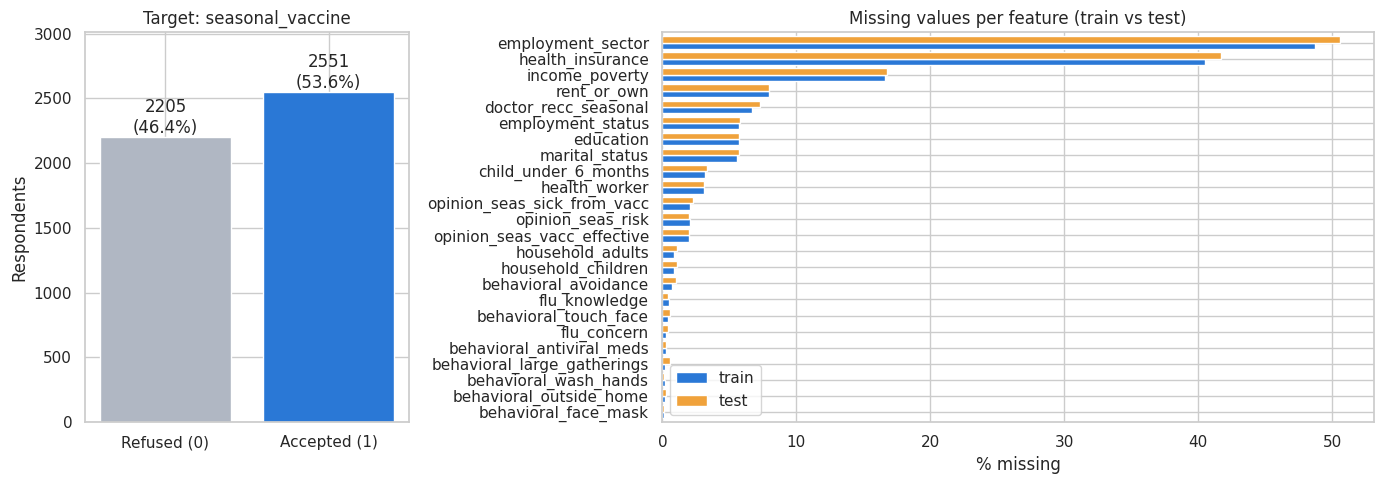

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 2.2]})

# (a) target balance
counts = train[TARGET].value_counts().sort_index()
ax[0].bar(["Refused (0)", "Accepted (1)"], counts.values, color=["#b0b7c3", "#2a78d6"])
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 30, f"{v}\n({v / len(train):.1%})", ha="center")
ax[0].set_ylim(0, counts.max() * 1.18)
ax[0].set_title("Target: seasonal_vaccine")
ax[0].set_ylabel("Respondents")

# (b) missingness, train vs test
miss = overview[["missing_train_%", "missing_test_%"]].drop([ID, TARGET])
miss = miss[miss.max(axis=1) > 0].sort_values("missing_train_%")
miss.plot.barh(ax=ax[1], color=["#2a78d6", "#f0a23b"], width=0.8)
ax[1].set_title("Missing values per feature (train vs test)")
ax[1].set_xlabel("% missing")
ax[1].legend(["train", "test"])
savefig("01_target_and_missingness")

### 2.3 Is missingness informative?
If people who skip a question behave differently, "missing" is a signal we should keep rather than hide with a plain imputation.

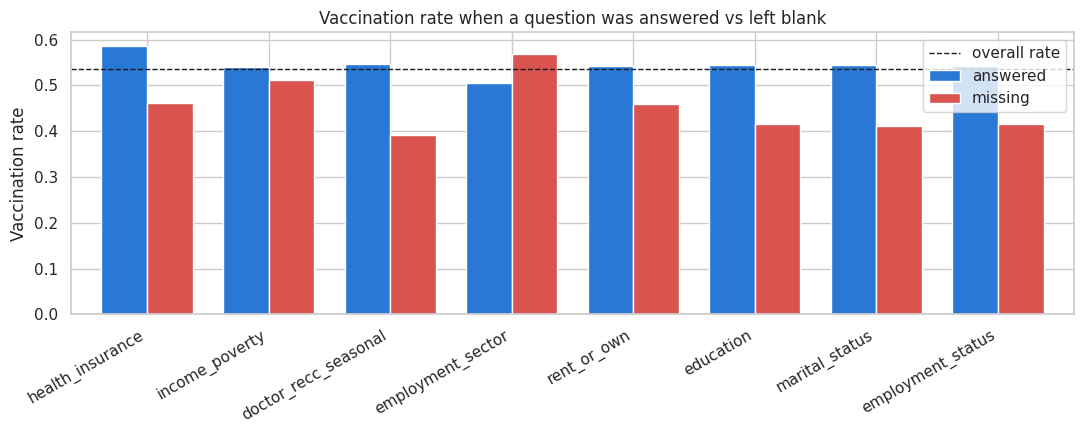

,answered,missing,n_missing
feature,,,
health_insurance,0.587,0.462,1925
income_poverty,0.541,0.513,790
doctor_recc_seasonal,0.547,0.393,321
employment_sector,0.506,0.568,2314
rent_or_own,0.543,0.459,381
education,0.544,0.415,270
marital_status,0.544,0.411,265
employment_status,0.544,0.416,269


In [6]:
rows = []
for c in ["health_insurance", "income_poverty", "doctor_recc_seasonal", "employment_sector",
          "rent_or_own", "education", "marital_status", "employment_status"]:
    m = train[c].isna()
    rows.append({"feature": c, "answered": train.loc[~m, TARGET].mean(),
                 "missing": train.loc[m, TARGET].mean(), "n_missing": m.sum()})
miss_rate = pd.DataFrame(rows).set_index("feature")

ax = miss_rate[["answered", "missing"]].plot.bar(figsize=(11, 4.5), color=["#2a78d6", "#d9534f"], width=0.75)
ax.axhline(train[TARGET].mean(), ls="--", color="k", lw=1, label="overall rate")
ax.set_ylabel("Vaccination rate"); ax.set_xlabel("")
ax.set_title("Vaccination rate when a question was answered vs left blank")
ax.legend(); plt.xticks(rotation=30, ha="right")
savefig("02_missingness_vs_target")
miss_rate.round(3)

### 2.4 Vaccination rate across the main features

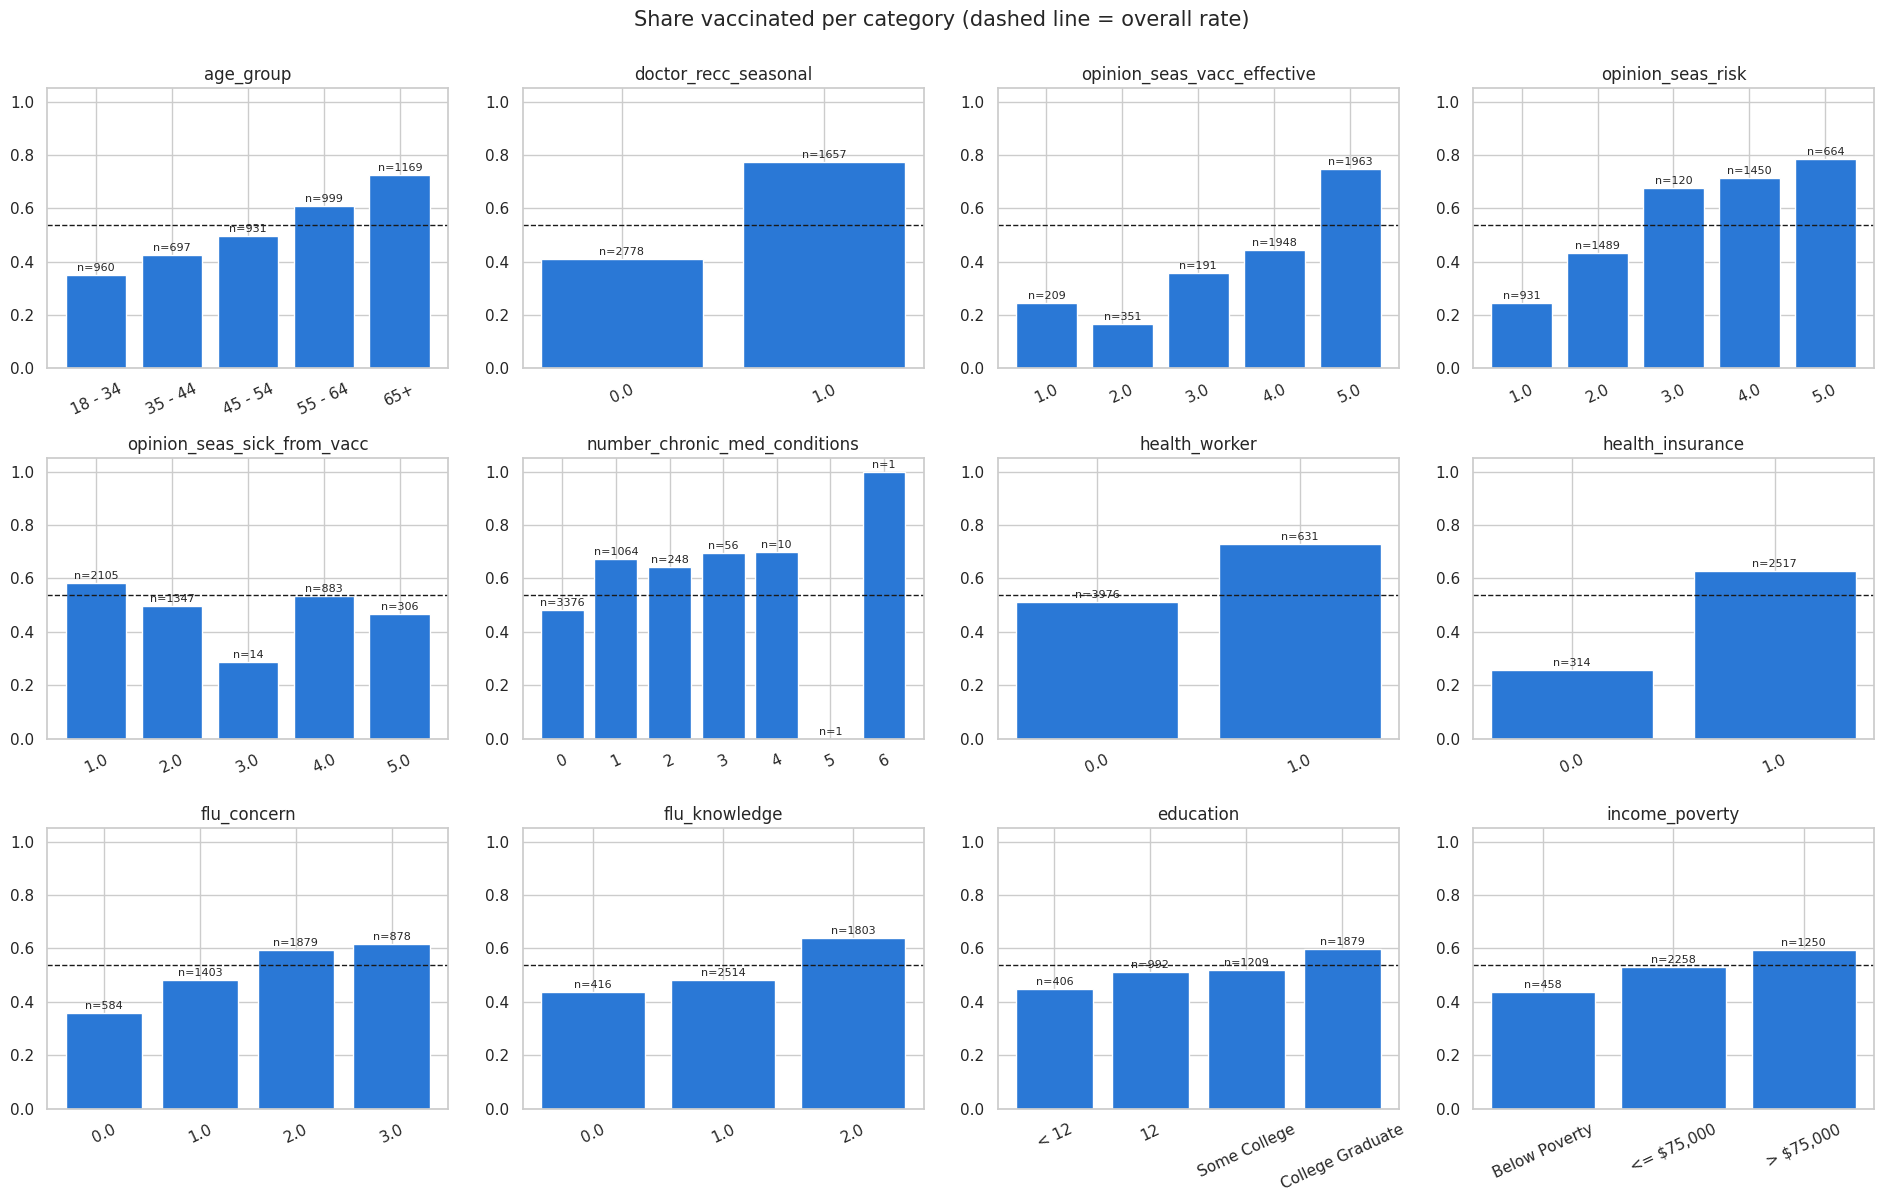

In [7]:
AGE_ORDER = ["18 - 34 Years", "35 - 44 Years", "45 - 54 Years", "55 - 64 Years", "65+ Years"]
EDU_ORDER = ["< 12 Years", "12 Years", "Some College", "College Graduate"]
INC_ORDER = ["Below Poverty", "<= $75,000, Above Poverty", "> $75,000"]

plot_feats = ["age_group", "doctor_recc_seasonal", "opinion_seas_vacc_effective",
              "opinion_seas_risk", "opinion_seas_sick_from_vacc", "number_chronic_med_conditions",
              "health_worker", "health_insurance", "flu_concern", "flu_knowledge",
              "education", "income_poverty"]
orders = {"age_group": AGE_ORDER, "education": EDU_ORDER, "income_poverty": INC_ORDER}
base = train[TARGET].mean()

fig, axes = plt.subplots(3, 4, figsize=(19, 12))
for ax, f in zip(axes.ravel(), plot_feats):
    g = train.groupby(f)[TARGET].agg(["mean", "count"])
    if f in orders:
        g = g.reindex(orders[f])
    ax.bar([str(i).replace(" Years", "").replace(", Above Poverty", "") for i in g.index],
           g["mean"], color="#2a78d6")
    for i, (m, n) in enumerate(zip(g["mean"], g["count"])):
        ax.text(i, m + 0.015, f"n={n}", ha="center", fontsize=8)
    ax.axhline(base, ls="--", color="k", lw=1)
    ax.set_ylim(0, 1.05); ax.set_title(f); ax.tick_params(axis="x", rotation=25)
fig.suptitle("Share vaccinated per category (dashed line = overall rate)", y=1.0, fontsize=15)
savefig("03_vaccination_rate_by_feature")

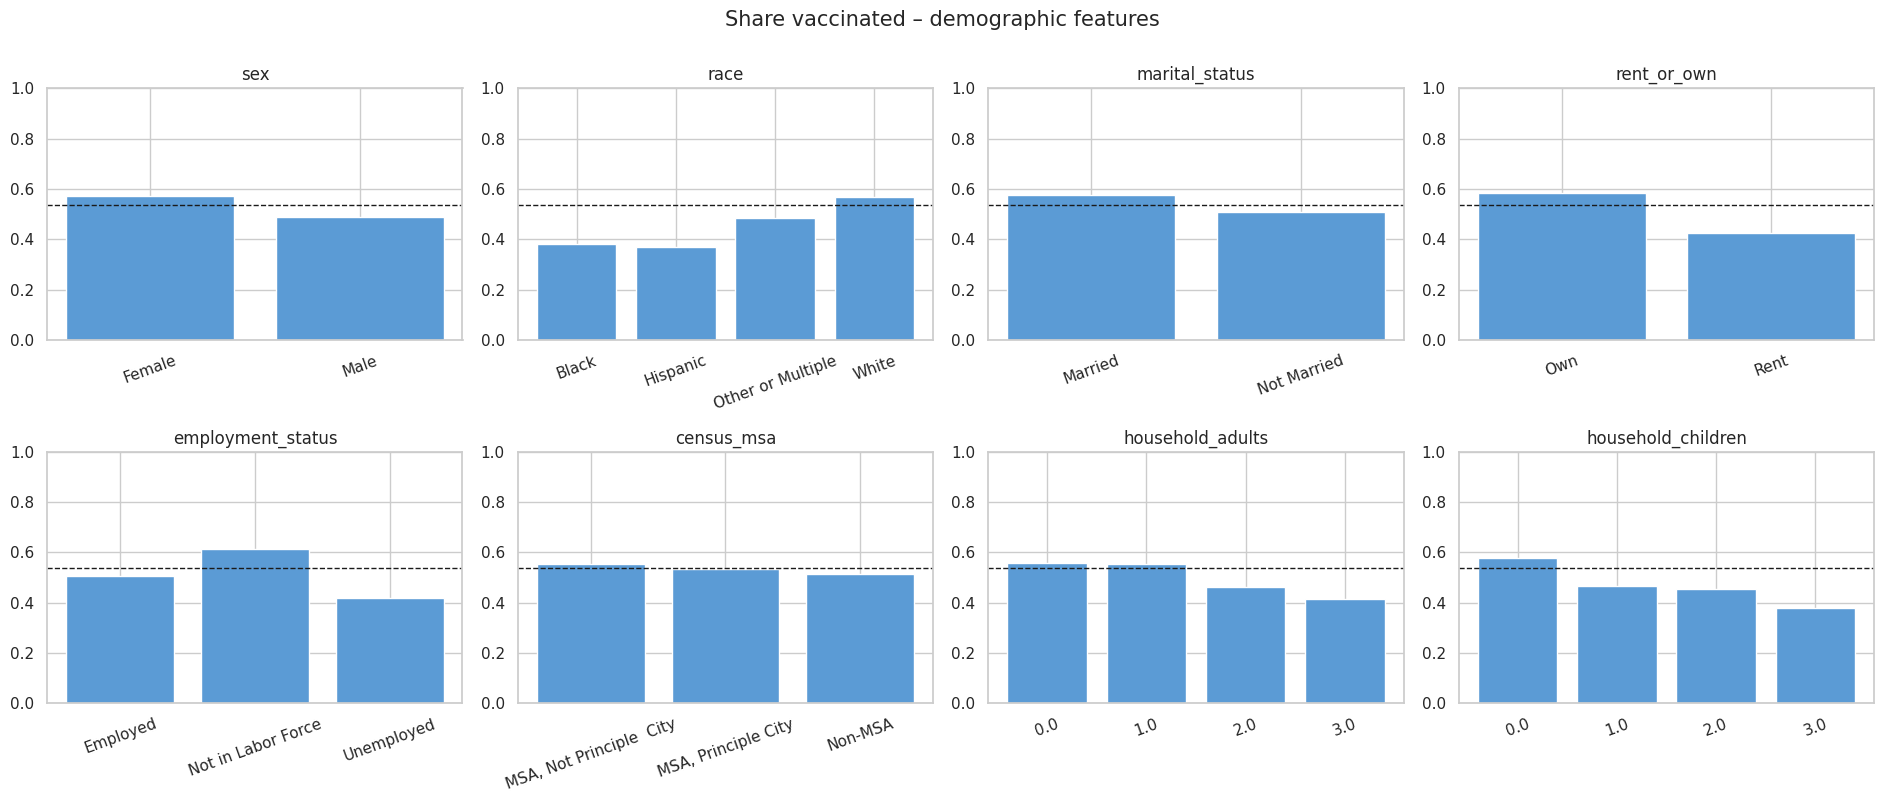

In [8]:
# Demographic / household features
demo = ["sex", "race", "marital_status", "rent_or_own", "employment_status",
        "census_msa", "household_adults", "household_children"]
fig, axes = plt.subplots(2, 4, figsize=(19, 8))
for ax, f in zip(axes.ravel(), demo):
    g = train.groupby(f)[TARGET].mean()
    ax.bar([str(i) for i in g.index], g.values, color="#5b9bd5")
    ax.axhline(base, ls="--", color="k", lw=1)
    ax.set_ylim(0, 1); ax.set_title(f); ax.tick_params(axis="x", rotation=20)
fig.suptitle("Share vaccinated – demographic features", y=1.0, fontsize=15)
savefig("04_vaccination_rate_demographics")

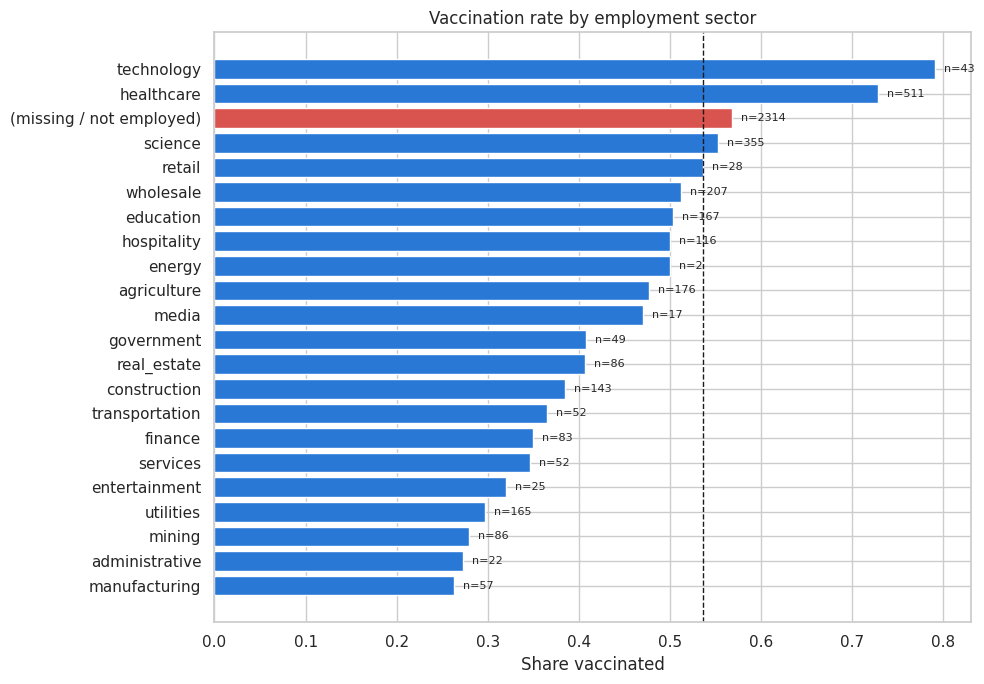

sector missing      False  True 
employment_status               
Employed             2442     25
NaN                     0    269
Not in Labor Force      0   1786
Unemployed              0    234


In [9]:
# Employment sector (49% missing = mostly people who are not employed)
sec = (train.assign(employment_sector=train["employment_sector"].fillna("(missing / not employed)"))
            .groupby("employment_sector")[TARGET].agg(["mean", "count"]).sort_values("mean"))
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(sec.index, sec["mean"], color=["#d9534f" if "missing" in i else "#2a78d6" for i in sec.index])
for i, (m, n) in enumerate(zip(sec["mean"], sec["count"])):
    ax.text(m + 0.01, i, f"n={n}", va="center", fontsize=8)
ax.axvline(base, ls="--", color="k", lw=1)
ax.set_xlabel("Share vaccinated"); ax.set_title("Vaccination rate by employment sector")
savefig("05_vaccination_rate_by_sector")
print(pd.crosstab(train["employment_status"].fillna("NaN"), train["employment_sector"].isna(),
                  colnames=["sector missing"]))

### 2.5 Correlations
Spearman is used because most numeric columns are ordinal survey scales, not continuous measurements.

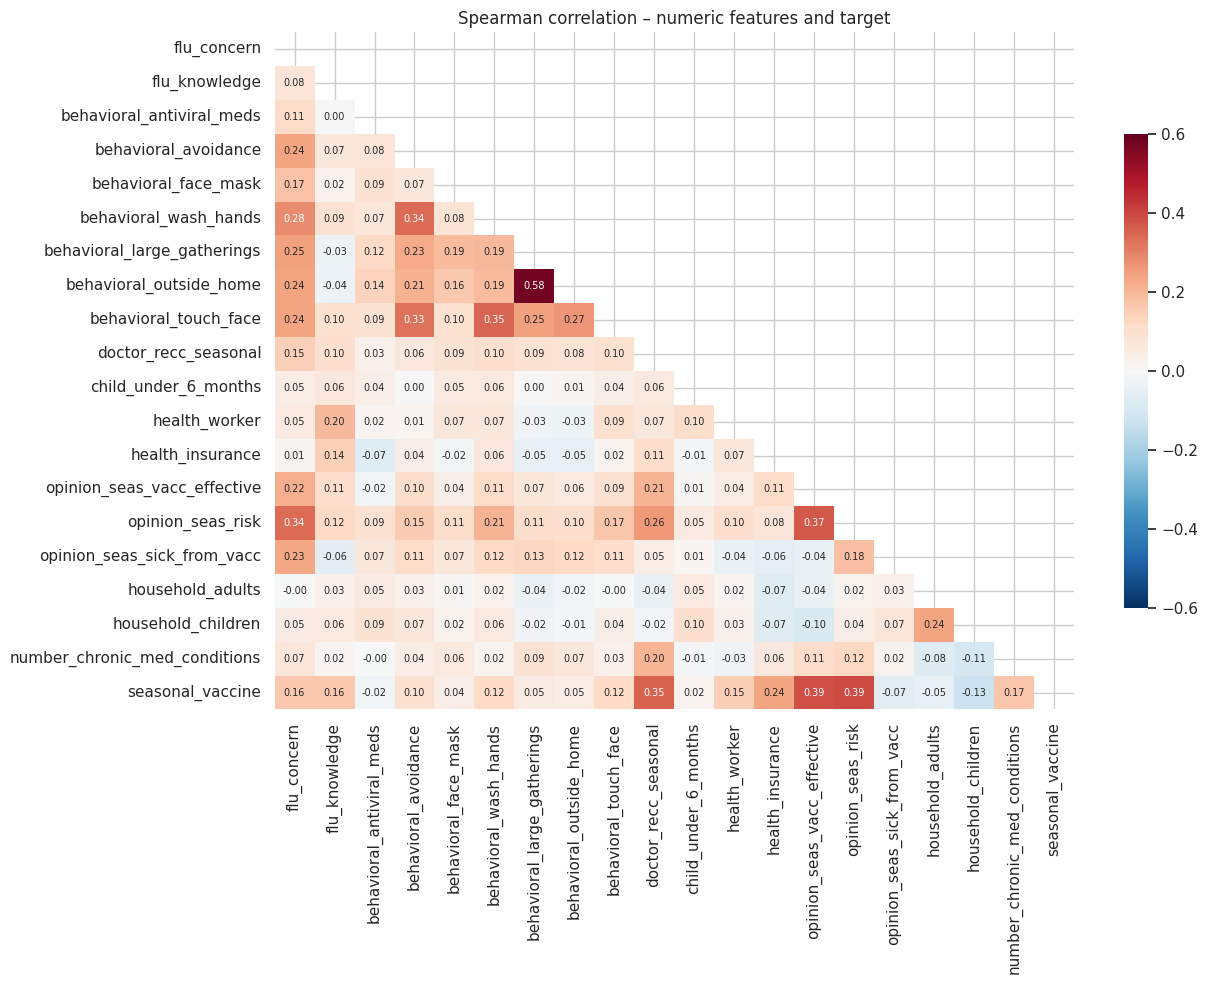

,seasonal_vaccine
opinion_seas_risk,0.393
opinion_seas_vacc_effective,0.387
doctor_recc_seasonal,0.355
health_insurance,0.236
number_chronic_med_conditions,0.165
flu_concern,0.162
flu_knowledge,0.161
health_worker,0.149


In [10]:
num_cols_all = train.drop(columns=[ID]).select_dtypes("number").columns
corr = train[num_cols_all].corr(method="spearman")
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, bool)), cmap="RdBu_r", center=0,
            vmin=-0.6, vmax=0.6, annot=True, fmt=".2f", annot_kws={"size": 7},
            cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Spearman correlation – numeric features and target")
savefig("06_correlation_heatmap")

corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).head(8).round(3)

### 2.6 Age × chronic conditions (the two drivers of hospitalisation risk)
These two columns matter twice: they predict who accepts the vaccine **and** they set how expensive a wrong decision is.

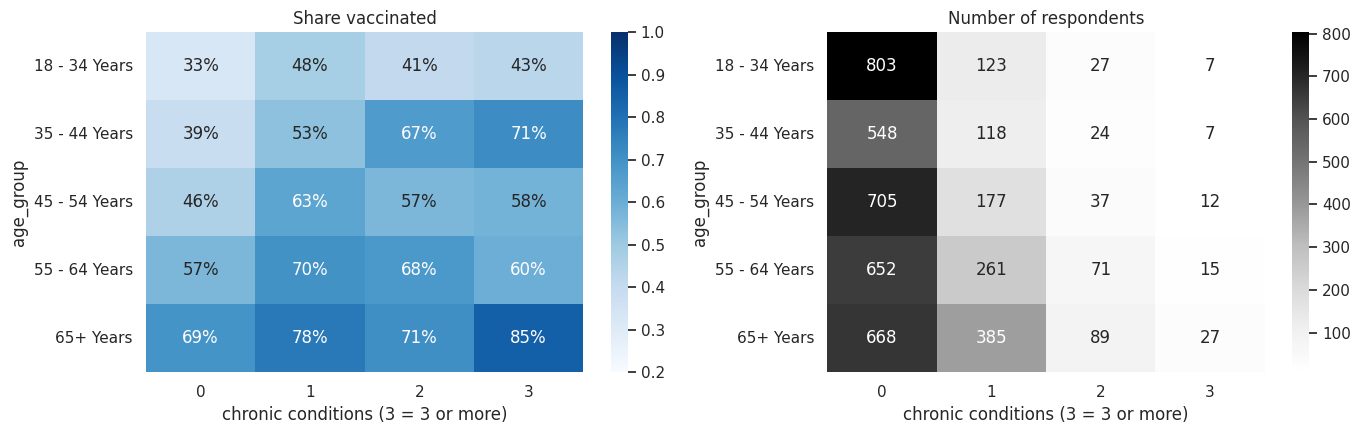

In [11]:
tmp = train.assign(chronic=train["number_chronic_med_conditions"].clip(upper=3))
rate = tmp.pivot_table(index="age_group", columns="chronic", values=TARGET, aggfunc="mean").reindex(AGE_ORDER)
cnt  = tmp.pivot_table(index="age_group", columns="chronic", values=TARGET, aggfunc="count").reindex(AGE_ORDER)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(rate, annot=True, fmt=".0%", cmap="Blues", vmin=0.2, vmax=1, ax=ax[0])
ax[0].set_title("Share vaccinated"); ax[0].set_xlabel("chronic conditions (3 = 3 or more)")
sns.heatmap(cnt, annot=True, fmt=".0f", cmap="Greys", ax=ax[1])
ax[1].set_title("Number of respondents"); ax[1].set_xlabel("chronic conditions (3 = 3 or more)")
savefig("07_age_x_chronic")

### EDA take-aways (drive the decisions below)
* **Size and balance:** 4,756 labelled rows, 29 usable features, no duplicates. The target is almost balanced (53.6% accepted), so no resampling is needed and accuracy is not misleading by itself – but it is still not our metric (section 3).
* **Strongest signals:** opinion about the risk of flu (Spearman 0.39), opinion about vaccine effectiveness (0.39) and a doctor's recommendation (0.36). Behavioural features (masks, hand washing…) are only weakly related to the target.
* **Age is monotonic:** acceptance climbs from 35% (18-34) to 73% (65+). Chronic conditions also raise acceptance.
* **Missing values are not random:** people who left `health_insurance` blank (40% of rows) vaccinate less (46% vs 59%); the same holds for `doctor_recc_seasonal` (39% vs 55%) and the demographic block (education, marital status, employment are missing together for ~270 people, who vaccinate at ~41%). → we test a pre-processing option that keeps missingness as information.
* **`employment_sector` is 49% missing, but structurally:** it is blank for everyone who is not employed, so "Missing" is a valid category, not an error. Healthcare stands out among sectors; several sectors have fewer than 30 rows → group rare ones.
* **Train and test look alike:** missing-value rates per column are almost identical, so we expect validation results to carry over to the test set.
* **No strong multicollinearity:** the largest feature-feature correlations are among the behavioural items (~0.5-0.6), which is fine for regularised logistic regression and trees.

## 3. The evaluation metric: total money spent by the town

We are not scored on accuracy. The brief gives us the rules, and we turned them into a cost formula.

**Rules from the brief**
* Everyone gets infected (probability of infection = 100%).
* A vaccine costs **\$300**, a hospitalisation costs **\$18,500**.
* A vaccine is posted to everyone we predict `1`. If the person refuses, it is wasted.
* If we predict `0` but the person wanted a vaccine, the town pays them the vaccine cost (\$300) and they stay unvaccinated.

**Cost of each outcome for one person** — $p_u$, $p_v$ = probability of hospitalisation if unvaccinated / vaccinated, $H$ = \$18,500:

| we predict | person really | vaccine money | expected hospital money |
|---|---|---|---|
| 1 | accepts (TP) | 300 | $p_v \cdot H$ |
| 1 | refuses (FP) | 300 (wasted) | $p_u \cdot H$ |
| 0 | wanted it (FN) | 300 (compensation) | $p_u \cdot H$ |
| 0 | refuses (TN) | 0 | $p_u \cdot H$ |

So a false positive and a false negative both cost \$300, a true positive costs \$300 but **saves** $(p_u - p_v)\cdot H$, and a true negative is free.

**Best decision per person.** If the model says the chance of acceptance is $q$, sending a vaccine is cheaper when

$$ q \;>\; \frac{300}{300 + (p_u - p_v)\,H} $$

The threshold is therefore **not 0.5 and not the same for everybody**: for high-risk people (large $p_u - p_v$) we should send a vaccine even if we are fairly unsure, for low-risk young people we should only send when we are almost certain.

### Hospitalisation probabilities (assumptions)
The dataset does not contain hospitalisation data, so, as the brief suggests, these come from generative-AI research cross-checked against published flu burden figures (CDC burden estimates for the H3N2-dominant 2017-18 season, and vaccine-effectiveness studies). **They are assumptions, not measurements** — section 7 tests how much our conclusions depend on them.

* Risk of hospitalisation given infection rises steeply with age (well under 1% for young adults, close to 10% for 65+).
* Each chronic condition in the list (lung, heart, diabetes, kidney, immune…) multiplies the risk.
* The vaccine reduces hospitalisation risk by roughly 40% in adults under 65 and roughly 30% in 65+ (H3N2 vaccines work less well in older adults).

In [12]:
VACCINE_COST = 300
HOSP_COST = 18_500

# P(hospitalised | infected, unvaccinated, no chronic condition) by age group
BASE_HOSP = {"18 - 34 Years": 0.004, "35 - 44 Years": 0.005, "45 - 54 Years": 0.008,
             "55 - 64 Years": 0.012, "65+ Years": 0.090}
# risk multiplier for 0, 1, 2, 3+ chronic conditions
CHRONIC_MULT = {0: 1.0, 1: 2.0, 2: 3.0, 3: 4.0}
# vaccine effectiveness against hospitalisation
VE_UNDER_65, VE_65_PLUS = 0.40, 0.30
MAX_PROB = 0.50   # cap so multipliers can never give silly probabilities

def hosp_probs(X, risk_scale=1.0, ve_scale=1.0):
    """Return (p_unvaccinated, p_vaccinated) for every row of X.
    risk_scale / ve_scale let us stress-test the assumptions (section 7)."""
    base = X["age_group"].map(BASE_HOSP).to_numpy()
    mult = X["number_chronic_med_conditions"].clip(upper=3).map(CHRONIC_MULT).to_numpy()
    p_u = np.minimum(base * mult * risk_scale, MAX_PROB)
    ve = np.where(X["age_group"].to_numpy() == "65+ Years", VE_65_PLUS, VE_UNDER_65)
    p_v = p_u * (1 - np.minimum(ve * ve_scale, 1.0))
    return p_u, p_v

def town_cost(y_true, y_pred, X, **kw):
    """Total expected money spent by the town for a set of predictions."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    p_u, p_v = hosp_probs(X, **kw)
    vaccine = VACCINE_COST * (y_pred + (1 - y_pred) * y_true)   # sent (used or wasted) + compensation
    hospital = HOSP_COST * np.where((y_pred == 1) & (y_true == 1), p_v, p_u)
    return float((vaccine + hospital).sum())

def cost_per_person(y_true, y_pred, X, **kw):
    return town_cost(y_true, y_pred, X, **kw) / len(y_true)

def cost_threshold(X, **kw):
    """Per-person probability threshold above which sending a vaccine is cheaper."""
    p_u, p_v = hosp_probs(X, **kw)
    return VACCINE_COST / (VACCINE_COST + (p_u - p_v) * HOSP_COST)

def cost_optimal_decision(q, X, **kw):
    """Turn acceptance probabilities q into the cheapest 0/1 decision."""
    return (np.asarray(q) > cost_threshold(X, **kw)).astype(int)

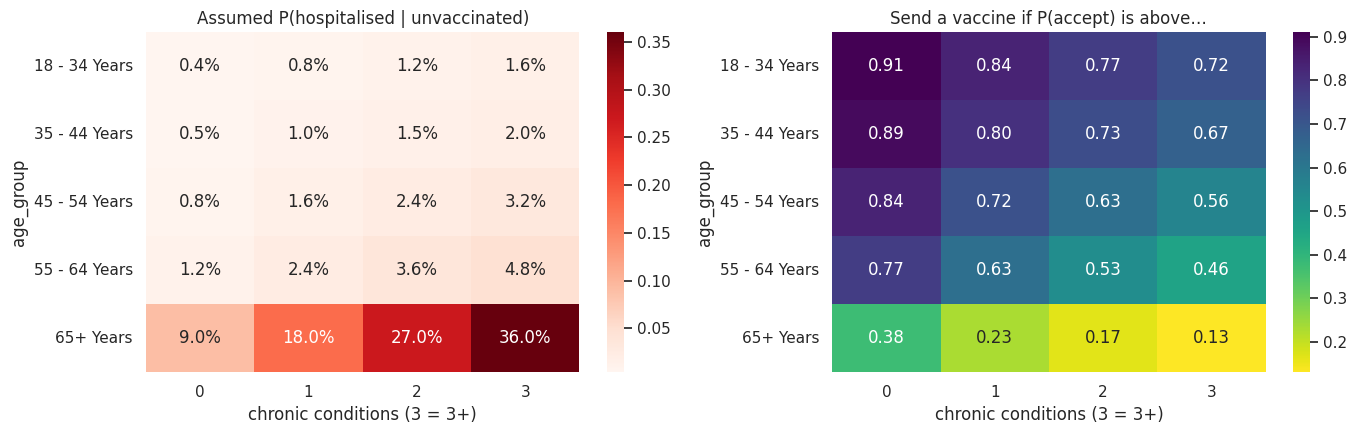

In [13]:
# What the assumptions mean in practice: risk table and decision threshold per group
grid = pd.DataFrame([(a, c) for a in AGE_ORDER for c in range(4)],
                    columns=["age_group", "number_chronic_med_conditions"])
grid["p_unvacc"], grid["p_vacc"] = hosp_probs(grid)
grid["threshold"] = cost_threshold(grid)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(grid.pivot(index="age_group", columns="number_chronic_med_conditions", values="p_unvacc").reindex(AGE_ORDER),
            annot=True, fmt=".1%", cmap="Reds", ax=ax[0])
ax[0].set_title("Assumed P(hospitalised | unvaccinated)"); ax[0].set_xlabel("chronic conditions (3 = 3+)")
sns.heatmap(grid.pivot(index="age_group", columns="number_chronic_med_conditions", values="threshold").reindex(AGE_ORDER),
            annot=True, fmt=".2f", cmap="viridis_r", ax=ax[1])
ax[1].set_title("Send a vaccine if P(accept) is above…"); ax[1].set_xlabel("chronic conditions (3 = 3+)")
savefig("08_risk_and_thresholds")

In [14]:
# Reference points on the training data: how much would trivial strategies cost?
X_all, y_all = train.drop(columns=[ID, TARGET]), train[TARGET]
refs = pd.Series({
    "send to nobody":    cost_per_person(y_all, np.zeros(len(y_all), int), X_all),
    "send to everybody": cost_per_person(y_all, np.ones(len(y_all), int), X_all),
    "perfect knowledge (lower bound)": cost_per_person(y_all, y_all, X_all),
}, name="cost per person ($)")
refs.round(2)

,cost per person ($)
send to nobody,936.27
send to everybody,903.62
perfect knowledge (lower bound),764.53


**Reading the references.** With our assumptions the town spends about \$936 per person if it sends nothing and \$904 if it posts a vaccine to everybody. Even a perfect predictor only gets down to about \$765, because most of the money is unavoidable hospitalisation of infected people. So the *whole* playing field between "no model" and "perfect model" is roughly \$140-170 per person – differences of a few dollars between models are meaningful on a town scale but small relative to the total.

## 4. Pre-processing

Decisions (each one comes from the EDA):

| Issue found in EDA | What we do | Why |
|---|---|---|
| `respondent_id` is a random identifier | dropped | carries no information |
| Survey scales (0-3, 1-5) and binaries | kept numeric, median-imputed, standardised | ordinal meaning preserved; scaling is needed by logistic regression |
| Text categories | one-hot encoded | no fake ordering for nominal variables such as race / sector |
| Rare employment sectors (some < 30 rows) | grouped as "infrequent" (`min_frequency=20`) | avoids noisy dummies |
| Missing values, often informative | option B keeps a "Missing" category / missing-indicator flags | option A (plain imputation) is kept as the baseline to compare |
| `number_chronic_med_conditions` has a long thin tail (4, 5, 6 → 12 rows) | capped at 3 | too few examples to learn from |

Everything is inside an sklearn `Pipeline`, so imputers/encoders are fitted **only on the training folds** (no leakage into validation data).

In [15]:
FEATURES = [c for c in train.columns if c not in (ID, TARGET)]
CAT_COLS = train[FEATURES].select_dtypes("object").columns.tolist()
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]

class ClipChronic:
    """Tiny transformer: cap the number of chronic conditions at 3."""
    def fit(self, X, y=None): return self
    def transform(self, X):
        X = X.copy()
        X["number_chronic_med_conditions"] = X["number_chronic_med_conditions"].clip(upper=3)
        return X
    def get_params(self, deep=True): return {}
    def set_params(self, **p): return self

def make_prep(option="B"):
    """A = plain imputation (baseline).  B = missingness kept as information."""
    if option == "A":
        num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
        cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                        ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    else:
        num = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler())])
        cat = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
                        ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20,
                                             sparse_output=False))])
    ct = ColumnTransformer([("num", num, NUM_COLS), ("cat", cat, CAT_COLS)],
                           verbose_feature_names_out=False)
    return Pipeline([("clip", ClipChronic()), ("ct", ct)])

def make_model(clf, option="B"):
    return Pipeline([("prep", make_prep(option)), ("clf", clf)])

### Hold-out split
20% of the labelled data is locked away now and only used once, at the end, as a final check. All tuning and cross-validation use the other 80%.

In [16]:
X_train, X_hold, y_train, y_hold = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=RANDOM_STATE)
print(X_train.shape, X_hold.shape, "| positive rate:", round(y_train.mean(), 3), round(y_hold.mean(), 3))

(3804, 29) (952, 29) | positive rate: 0.536 0.537


In [17]:
def evaluate_cv(model, X, y, n_splits=5, n_repeats=3):
    """Repeated stratified CV. Returns one row per fold with classic metrics and the town cost
    under (i) our per-person cost rule and (ii) the naive 0.5 threshold."""
    cv = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=RANDOM_STATE)
    rows = []
    for k, (tr, va) in enumerate(cv.split(X, y)):
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])
        Xv, yv = X.iloc[va], y.iloc[va]
        q = m.predict_proba(Xv)[:, 1]
        rows.append({"fold": k, "auc": roc_auc_score(yv, q), "logloss": log_loss(yv, q),
                     "accuracy": accuracy_score(yv, q >= 0.5),
                     "cost_rule": cost_per_person(yv, cost_optimal_decision(q, Xv), Xv),
                     "cost_0.5": cost_per_person(yv, (q >= 0.5).astype(int), Xv)})
    return pd.DataFrame(rows)

### Comparing the two pre-processing options
Same model, same folds, only the pre-processing changes.

In [18]:
prep_results = {}
for opt in ["A", "B"]:
    for name, clf in [("LogReg", LogisticRegression(max_iter=2000)),
                      ("HistGB", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]:
        prep_results[(name, f"prep {opt}")] = evaluate_cv(make_model(clf, opt), X_train, y_train)
prep_table = pd.concat({k: v.drop(columns="fold").agg(["mean", "std"]).T.stack() for k, v in prep_results.items()}, axis=1).T
prep_table.round(4)

auc         logloss         accuracy         cost_rule  \
                 mean     std    mean     std     mean     std      mean   
LogReg prep A  0.8459  0.0150  0.4907  0.0226   0.7777  0.0140  799.5620   
HistGB prep A  0.8390  0.0123  0.5044  0.0226   0.7645  0.0135  798.9483   
LogReg prep B  0.8469  0.0153  0.4918  0.0237   0.7788  0.0159  798.2034   
HistGB prep B  0.8412  0.0128  0.5018  0.0234   0.7669  0.0135  798.4745   

                        cost_0.5           
                   std      mean      std  
LogReg prep A  38.8593  810.0934  38.9327  
HistGB prep A  37.9808  815.8148  38.7087  
LogReg prep B  39.4204  811.1402  39.9149  
HistGB prep B  38.9880  816.3074  39.5655

**Result.** Keeping missingness as information (option B) is slightly cheaper for both models (logistic regression \$798.2 vs \$799.6, gradient boosting \$798.5 vs \$798.9), but the gain is far smaller than the fold-to-fold standard deviation (~\$39), so we cannot claim it is a real improvement. We keep option B because it is never worse, it handles the structural `employment_sector` gap correctly, and it groups rare categories. *Critical note:* the EDA showed missingness correlates with the target, yet the models gain little – most of that information is already carried by the strong opinion/doctor features.

## 5. Modelling and hyper-parameter tuning

| Model | Why it suits this dataset |
|---|---|
| Dummy (always predicts the base rate) | sanity floor – any real model must beat it |
| Logistic regression | survey scales have roughly monotonic effects (EDA 2.4); simple, well-calibrated probabilities, easy to explain |
| Random forest | captures interactions (e.g. age × doctor recommendation) without feature engineering |
| Histogram gradient boosting | usually the strongest model on tabular data of this size |
| Soft-voting ensemble of the three | averaging different model families reduces variance |

We tune on **log-loss**, not accuracy: our decision rule compares the predicted probability with a per-person threshold, so we need *good probabilities*, not just good 0/1 labels.

In [19]:
inner_cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

searches = {
    "LogReg": GridSearchCV(
        make_model(LogisticRegression(max_iter=3000)),
        {"clf__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
        scoring="neg_log_loss", cv=inner_cv, n_jobs=-1),
    "RandomForest": RandomizedSearchCV(
        make_model(RandomForestClassifier(n_estimators=400, random_state=RANDOM_STATE, n_jobs=1)),
        {"clf__max_depth": [6, 8, 10, 14, None], "clf__min_samples_leaf": [1, 3, 5, 10, 20],
         "clf__max_features": ["sqrt", 0.2, 0.3, 0.5]},
        n_iter=15, scoring="neg_log_loss", cv=inner_cv, n_jobs=-1, random_state=RANDOM_STATE),
    "HistGB": RandomizedSearchCV(
        make_model(HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
        {"clf__learning_rate": [0.02, 0.03, 0.05, 0.1], "clf__max_iter": [100, 200, 300, 500],
         "clf__max_depth": [2, 3, 4, 6], "clf__min_samples_leaf": [10, 20, 40, 80],
         "clf__l2_regularization": [0, 0.1, 1, 10]},
        n_iter=25, scoring="neg_log_loss", cv=inner_cv, n_jobs=-1, random_state=RANDOM_STATE),
}
best = {}
for name, s in searches.items():
    s.fit(X_train, y_train)
    best[name] = s.best_estimator_
    print(f"{name:13s} best CV log-loss = {-s.best_score_:.4f} | {s.best_params_}")

LogReg        best CV log-loss = 0.4930 | {'clf__C': 0.1}
RandomForest  best CV log-loss = 0.4892 | {'clf__min_samples_leaf': 1, 'clf__max_features': 0.3, 'clf__max_depth': 14}
HistGB        best CV log-loss = 0.4784 | {'clf__min_samples_leaf': 10, 'clf__max_iter': 200, 'clf__max_depth': 3, 'clf__learning_rate': 0.05, 'clf__l2_regularization': 0.1}


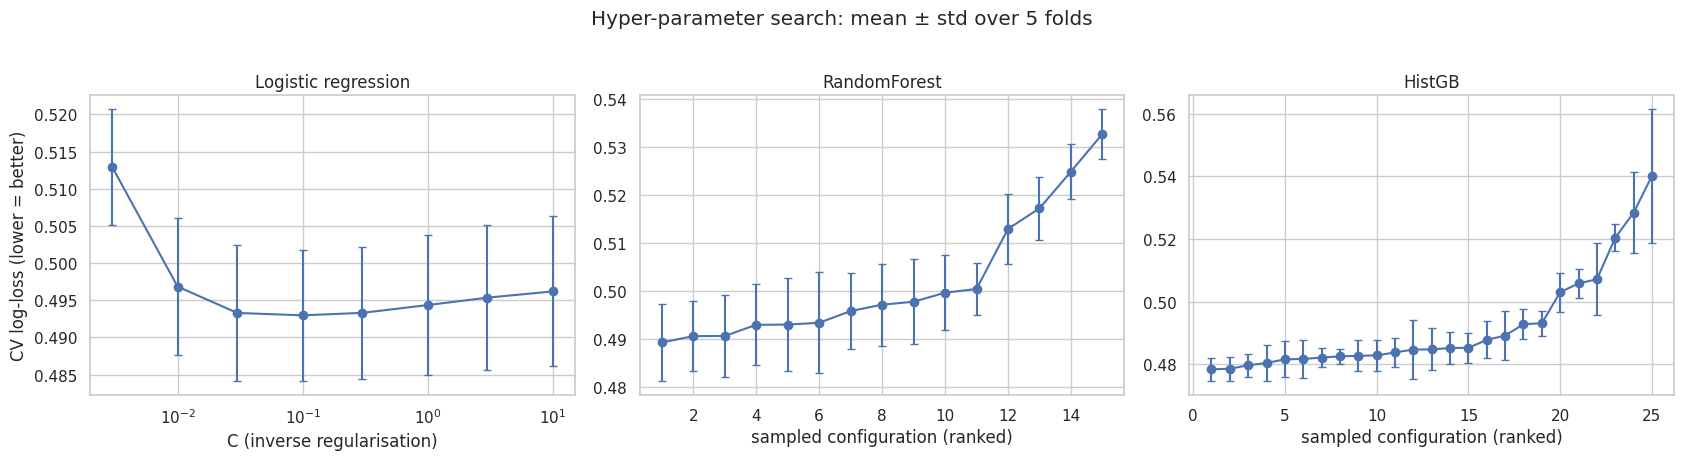

In [20]:
# How sensitive is each model to its hyper-parameters?
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
r = pd.DataFrame(searches["LogReg"].cv_results_)
ax[0].errorbar(r["param_clf__C"].astype(float), -r["mean_test_score"], yerr=r["std_test_score"], marker="o", capsize=3)
ax[0].set_xscale("log"); ax[0].set_xlabel("C (inverse regularisation)"); ax[0].set_ylabel("CV log-loss (lower = better)")
ax[0].set_title("Logistic regression")
for a, name in zip(ax[1:], ["RandomForest", "HistGB"]):
    r = pd.DataFrame(searches[name].cv_results_).sort_values("mean_test_score", ascending=False)
    a.errorbar(range(1, len(r) + 1), -r["mean_test_score"], yerr=r["std_test_score"], marker="o", capsize=3)
    a.set_xlabel("sampled configuration (ranked)"); a.set_title(name)
fig.suptitle("Hyper-parameter search: mean ± std over 5 folds", y=1.02)
savefig("09_hyperparameter_search")

In [21]:
# Final candidate models
models = {
    "Dummy": make_model(DummyClassifier(strategy="prior")),
    "LogReg": best["LogReg"],
    "RandomForest": best["RandomForest"],
    "HistGB": best["HistGB"],
    "Ensemble": VotingClassifier([(n, clone(best[n])) for n in ["LogReg", "RandomForest", "HistGB"]],
                                 voting="soft"),
}

## 6. Performance analysis

### 6.1 Repeated cross-validation (5 folds × 3 repeats = 15 scores per model)
The spread across folds tells us how big random variation is, so we know which differences between models are real.

In [22]:
cv_results = {name: evaluate_cv(m, X_train, y_train) for name, m in models.items()}
summary = pd.concat({n: r.drop(columns="fold").agg(["mean", "std"]).T.stack() for n, r in cv_results.items()}, axis=1).T
summary.round(4)

auc         logloss         accuracy         cost_rule  \
                mean     std    mean     std     mean     std      mean   
Dummy         0.5000  0.0000  0.6905  0.0000   0.5363  0.0003  808.9513   
LogReg        0.8470  0.0149  0.4906  0.0216   0.7762  0.0176  798.3829   
RandomForest  0.8427  0.0125  0.4921  0.0158   0.7727  0.0148  798.2268   
HistGB        0.8508  0.0146  0.4809  0.0195   0.7747  0.0153  795.9689   
Ensemble      0.8534  0.0137  0.4780  0.0174   0.7767  0.0142  796.5442   

                       cost_0.5           
                  std      mean      std  
Dummy         38.1456  898.4206  37.4732  
LogReg        39.3090  812.1020  39.1403  
RandomForest  38.1066  813.9656  39.3779  
HistGB        38.2566  812.1377  39.4850  
Ensemble      38.3544  811.4376  38.9617

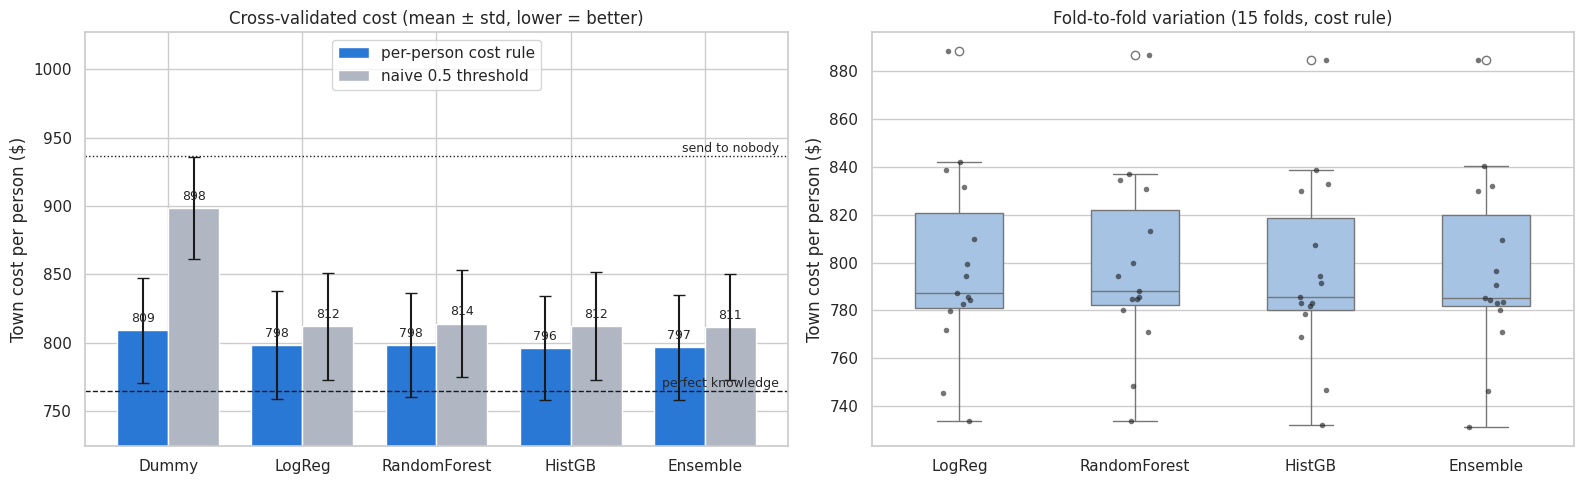

In [23]:
names = list(models)
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

# (a) cost per person: our rule vs naive 0.5 threshold
x = np.arange(len(names)); w = 0.38
for i, (col, lab, colr) in enumerate([("cost_rule", "per-person cost rule", "#2a78d6"),
                                       ("cost_0.5", "naive 0.5 threshold", "#b0b7c3")]):
    mu = [cv_results[n][col].mean() for n in names]; sd = [cv_results[n][col].std() for n in names]
    ax[0].bar(x + (i - 0.5) * w, mu, w, yerr=sd, capsize=4, label=lab, color=colr)
    for xi, m in zip(x + (i - 0.5) * w, mu):
        ax[0].text(xi, m + 6, f"{m:.0f}", ha="center", fontsize=9)
for lab, v, ls in [("send to nobody", refs.iloc[0], ":"), ("perfect knowledge", refs.iloc[2], "--")]:
    ax[0].axhline(v, color="k", ls=ls, lw=1); ax[0].text(len(names) - 0.45, v + 3, lab, fontsize=9, ha="right")
lo = refs.iloc[2] - 40
ax[0].set_ylim(lo, max(refs.iloc[0], max(cv_results["Dummy"]["cost_0.5"])) + 40)
ax[0].set_xticks(x); ax[0].set_xticklabels(names)
ax[0].set_ylabel("Town cost per person ($)"); ax[0].set_title("Cross-validated cost (mean ± std, lower = better)")
ax[0].legend(loc="upper center")

# (b) fold-by-fold distribution of the cost
box = pd.concat([cv_results[n][["cost_rule"]].assign(model=n) for n in names if n != "Dummy"])
sns.boxplot(data=box, x="model", y="cost_rule", ax=ax[1], color="#9cc3ee", width=0.5)
sns.stripplot(data=box, x="model", y="cost_rule", ax=ax[1], color="k", size=4, alpha=0.6)
ax[1].set_ylabel("Town cost per person ($)"); ax[1].set_xlabel("")
ax[1].set_title("Fold-to-fold variation (15 folds, cost rule)")
savefig("10_cv_cost_comparison")

In [24]:
# Paired comparison: on the SAME folds, how often does each model beat logistic regression?
paired = pd.DataFrame({n: cv_results[n]["cost_rule"] - cv_results["LogReg"]["cost_rule"]
                       for n in ["RandomForest", "HistGB", "Ensemble"]})
pd.DataFrame({"mean diff vs LogReg ($/person)": paired.mean(), "std": paired.std(),
              "folds where it is cheaper": (paired < 0).sum().astype(str) + "/15"}).round(2)

,mean diff vs LogReg ($/person),std,folds where it is cheaper
RandomForest,-0.16,2.52,9/15
HistGB,-2.41,2.27,12/15
Ensemble,-1.84,2.21,11/15


### 6.2 Final check on the untouched hold-out set

In [25]:
fitted, hold_q, rows = {}, {}, []
for name, m in models.items():
    fitted[name] = clone(m).fit(X_train, y_train)
    q = hold_q[name] = fitted[name].predict_proba(X_hold)[:, 1]
    rows.append({"model": name, "auc": roc_auc_score(y_hold, q), "logloss": log_loss(y_hold, q),
                 "accuracy": accuracy_score(y_hold, q >= 0.5),
                 "cost_rule": cost_per_person(y_hold, cost_optimal_decision(q, X_hold), X_hold),
                 "cost_0.5": cost_per_person(y_hold, (q >= 0.5).astype(int), X_hold)})
hold_table = pd.DataFrame(rows).set_index("model")
print("Hold-out references ($/person): nobody = %.1f | everybody = %.1f | perfect = %.1f" % (
    cost_per_person(y_hold, np.zeros(len(y_hold), int), X_hold),
    cost_per_person(y_hold, np.ones(len(y_hold), int), X_hold),
    cost_per_person(y_hold, y_hold, X_hold)))
hold_table.round(4)

Hold-out references ($/person): nobody = 966.3 | everybody = 924.3 | perfect = 785.4


,auc,logloss,accuracy,cost_rule,cost_0.5
model,,,,,
Dummy,0.5000,0.6904,0.5368,834.3462,924.3284
LogReg,0.8536,0.4778,0.7815,824.5081,840.0909
RandomForest,0.8363,0.4998,0.7679,823.3117,844.6863
HistGB,0.8557,0.4730,0.7815,823.6647,837.3554
Ensemble,0.8548,0.4743,0.7857,822.4126,837.5867


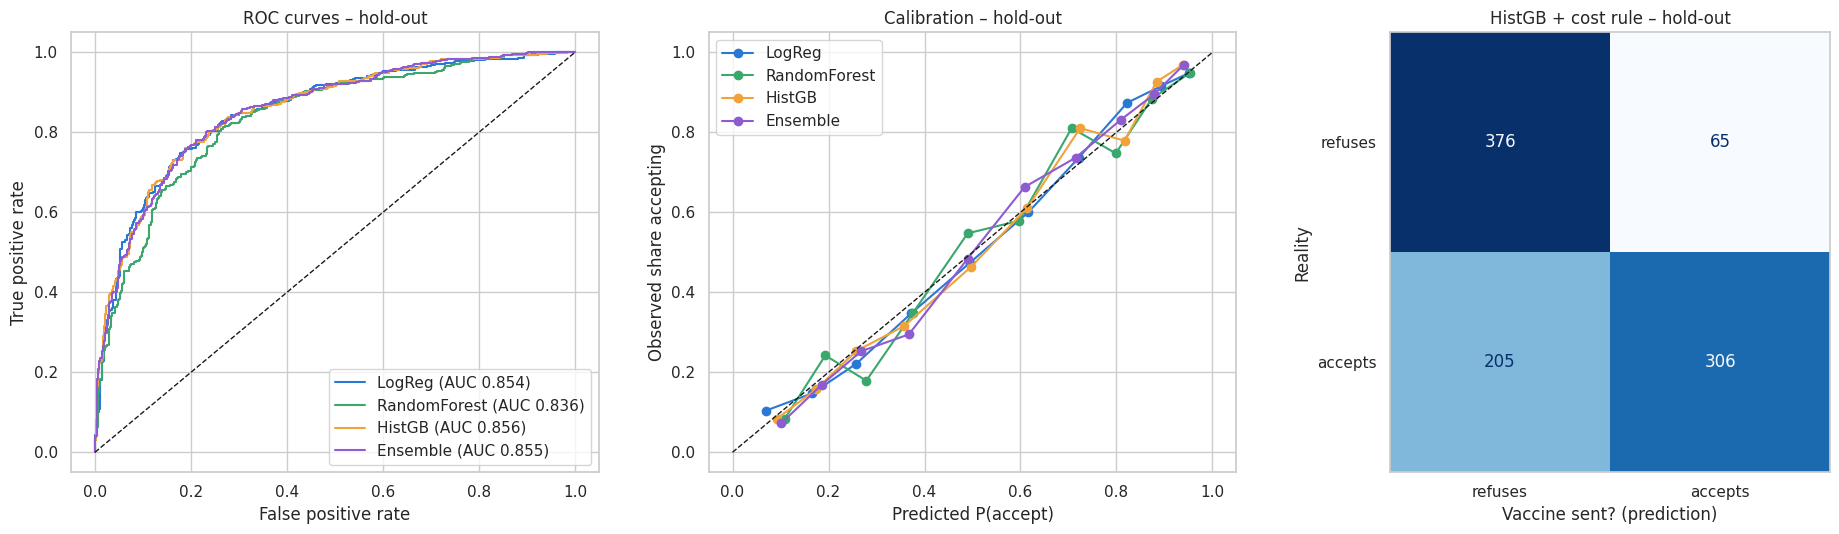

Best by CV: HistGB | best on hold-out: Ensemble


In [26]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5.5))
pal = dict(zip(["LogReg", "RandomForest", "HistGB", "Ensemble"], ["#2a78d6", "#3aa76d", "#f0a23b", "#8e5bd0"]))

# (a) ROC
for n, c in pal.items():
    fpr, tpr, _ = roc_curve(y_hold, hold_q[n])
    ax[0].plot(fpr, tpr, color=c, label=f"{n} (AUC {roc_auc_score(y_hold, hold_q[n]):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC curves – hold-out"); ax[0].legend()

# (b) calibration: are the probabilities trustworthy?
for n, c in pal.items():
    pt, pp = calibration_curve(y_hold, hold_q[n], n_bins=10, strategy="quantile")
    ax[1].plot(pp, pt, marker="o", color=c, label=n)
ax[1].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].set_xlabel("Predicted P(accept)"); ax[1].set_ylabel("Observed share accepting")
ax[1].set_title("Calibration – hold-out"); ax[1].legend()

# (c) confusion matrix of the best model under the cost rule
best_name = hold_table.drop("Dummy")["cost_rule"].idxmin()
cv_best_name = summary.drop("Dummy")[("cost_rule", "mean")].idxmin()
pred = cost_optimal_decision(hold_q[cv_best_name], X_hold)
ConfusionMatrixDisplay(confusion_matrix(y_hold, pred), display_labels=["refuses", "accepts"]).plot(
    ax=ax[2], cmap="Blues", colorbar=False)
ax[2].grid(False); ax[2].set_title(f"{cv_best_name} + cost rule – hold-out")
ax[2].set_xlabel("Vaccine sent? (prediction)"); ax[2].set_ylabel("Reality")
savefig("11_holdout_roc_calibration_confusion")
print("Best by CV:", cv_best_name, "| best on hold-out:", best_name)

### 6.3 Why one threshold for everyone is not enough
Out-of-fold probabilities for the whole labelled set let us sweep a single global threshold and compare it with the per-person rule.

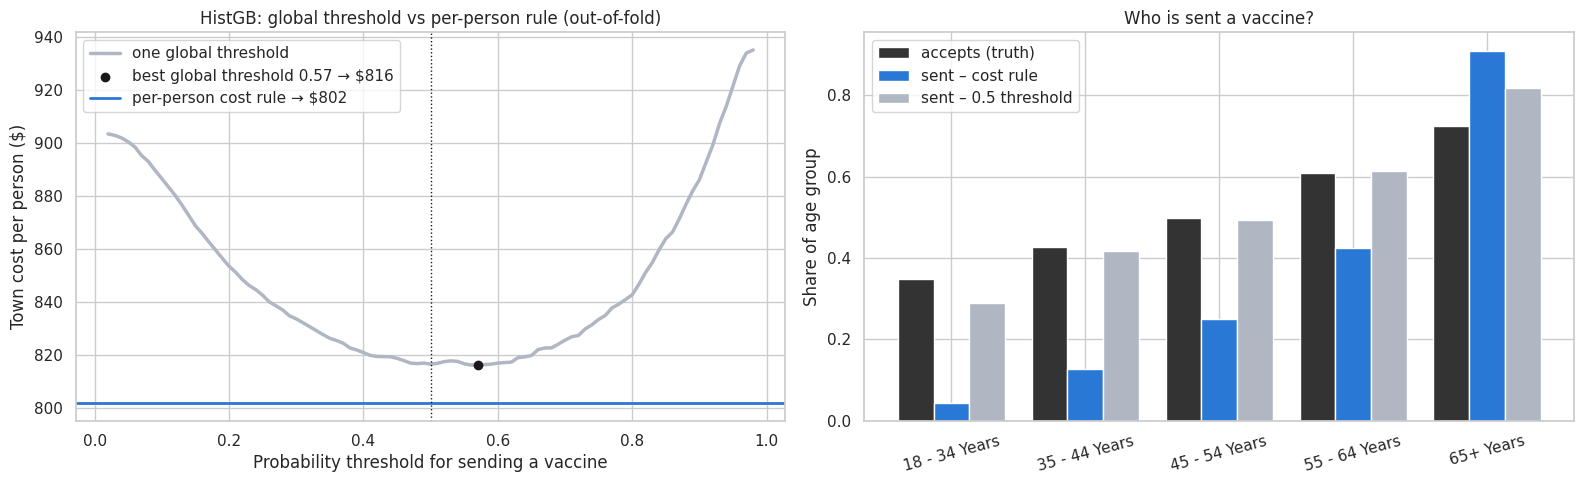

In [27]:
oof_cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
oof = {n: cross_val_predict(clone(models[n]), X_all, y_all, cv=oof_cv, method="predict_proba")[:, 1]
       for n in ["LogReg", "RandomForest", "HistGB", "Ensemble"]}

q = oof[cv_best_name]
ths = np.linspace(0.02, 0.98, 97)
sweep = [cost_per_person(y_all, (q >= t).astype(int), X_all) for t in ths]
rule_cost = cost_per_person(y_all, cost_optimal_decision(q, X_all), X_all)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].plot(ths, sweep, color="#b0b7c3", lw=2.5, label="one global threshold")
ax[0].scatter(ths[int(np.argmin(sweep))], min(sweep), color="k", zorder=3,
              label=f"best global threshold {ths[int(np.argmin(sweep))]:.2f} → ${min(sweep):.0f}")
ax[0].axhline(rule_cost, color="#2a78d6", lw=2, label=f"per-person cost rule → ${rule_cost:.0f}")
ax[0].axvline(0.5, color="k", ls=":", lw=1)
ax[0].set_xlabel("Probability threshold for sending a vaccine"); ax[0].set_ylabel("Town cost per person ($)")
ax[0].set_title(f"{cv_best_name}: global threshold vs per-person rule (out-of-fold)"); ax[0].legend()

# who gets a vaccine under each rule?
d = pd.DataFrame({"age_group": X_all["age_group"], "accepts (truth)": y_all,
                  "sent – cost rule": cost_optimal_decision(q, X_all), "sent – 0.5 threshold": (q >= 0.5).astype(int)})
d.groupby("age_group").mean().reindex(AGE_ORDER).plot.bar(ax=ax[1], color=["#333333", "#2a78d6", "#b0b7c3"], width=0.8)
ax[1].set_ylabel("Share of age group"); ax[1].set_xlabel(""); ax[1].tick_params(axis="x", rotation=15)
ax[1].set_title("Who is sent a vaccine?")
savefig("12_threshold_sweep_and_allocation")

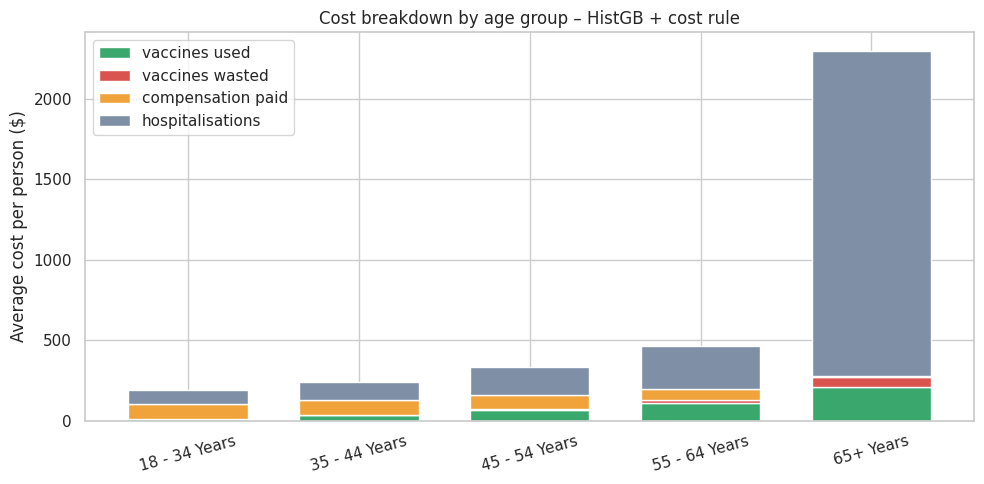

,vaccines used,vaccines wasted,compensation paid,hospitalisations
age_group,,,,
18 - 34 Years,11.9,0.9,92.8,87.4
35 - 44 Years,35.7,2.2,92.1,110.2
45 - 54 Years,64.1,10.6,85.1,173.4
55 - 64 Years,111.4,15.6,71.2,265.3
65+ Years,211.7,61.1,5.9,2019.9


In [28]:
# Where does the money go? Cost breakdown per age group for the best model (out-of-fold)
p_u, p_v = hosp_probs(X_all)
dec = cost_optimal_decision(q, X_all); yt = y_all.to_numpy()
parts = pd.DataFrame({
    "age_group": X_all["age_group"].to_numpy(),
    "vaccines used": VACCINE_COST * ((dec == 1) & (yt == 1)),
    "vaccines wasted": VACCINE_COST * ((dec == 1) & (yt == 0)),
    "compensation paid": VACCINE_COST * ((dec == 0) & (yt == 1)),
    "hospitalisations": HOSP_COST * np.where((dec == 1) & (yt == 1), p_v, p_u)})
breakdown = parts.groupby("age_group").mean().reindex(AGE_ORDER)
ax = breakdown.plot.bar(stacked=True, figsize=(10, 5), color=["#3aa76d", "#d9534f", "#f0a23b", "#7f8fa6"], width=0.7)
ax.set_ylabel("Average cost per person ($)"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=15)
ax.set_title(f"Cost breakdown by age group – {cv_best_name} + cost rule")
savefig("13_cost_breakdown_by_age")
breakdown.round(1)

### What the performance analysis tells us
* **The decision rule matters more than the model.** Switching from the 0.5 threshold to the per-person cost rule saves ~\$14-16 per person for every model. Switching between tuned models changes the cost by only ~\$2. Even the *Dummy* model (which knows nothing about individuals) reaches \$809 with the cost rule, because the rule alone already sends vaccines to the high-risk groups.
* **What the model adds:** the best model (HistGB, \$796.0) is ~\$13 per person cheaper than Dummy + rule and ~\$140 cheaper than sending nothing; it closes most of the gap to the perfect-knowledge bound (\$765).
* **Models are close.** AUC is 0.84-0.85 for all of them. The fold standard deviation (~\$38) mostly reflects *who happens to be in the fold* (how many 65+), not model instability – that is why we look at the **paired** differences: HistGB is cheaper than logistic regression in 12 of 15 folds (−\$2.4 ± 2.3), the ensemble in 11 of 15, the random forest is a coin-flip (9/15).
* **Hold-out agrees on the level, not the order.** All four models land within \$2 of each other on the hold-out (\$822-825); the ensemble is marginally first there, HistGB first in CV. With differences this small the order between HistGB and the ensemble is not statistically settled; we rank by CV because it averages over 15 validation sets instead of one.
* **Calibration** is good for all models (points close to the diagonal), which is what the cost rule needs.
* **A single global threshold cannot match the rule:** the best global threshold (0.57) still costs \$816 vs \$802 for the per-person rule (out-of-fold, all data).
* **Who gets a vaccine:** the rule posts vaccines to ~90% of the 65+ group (more than actually accept: a wasted \$300 is cheap next to an avoided hospitalisation) and to only ~5% of 18-34 year-olds (we would rather pay the \$300 compensation than risk wasting vaccines, since the health saving is ~\$30).
* **Limitations:** hyper-parameters were tuned on the same 80% used for the CV table, so those scores are slightly optimistic (the hold-out is the unbiased check); costs are *expected* values built on assumed hospitalisation risks.

## 7. Sensitivity analysis: what if our hospitalisation assumptions are wrong?
The hospitalisation probabilities are the weakest part of the pipeline (they are researched assumptions, and the organisers will score us with *their* numbers). We recompute the cost while halving / doubling the risk and the vaccine effectiveness.

Two questions:
1. Does the **ranking of models** change? (Which files to submit.)
2. How much do we lose if we **decide with our assumptions but the truth is different**?

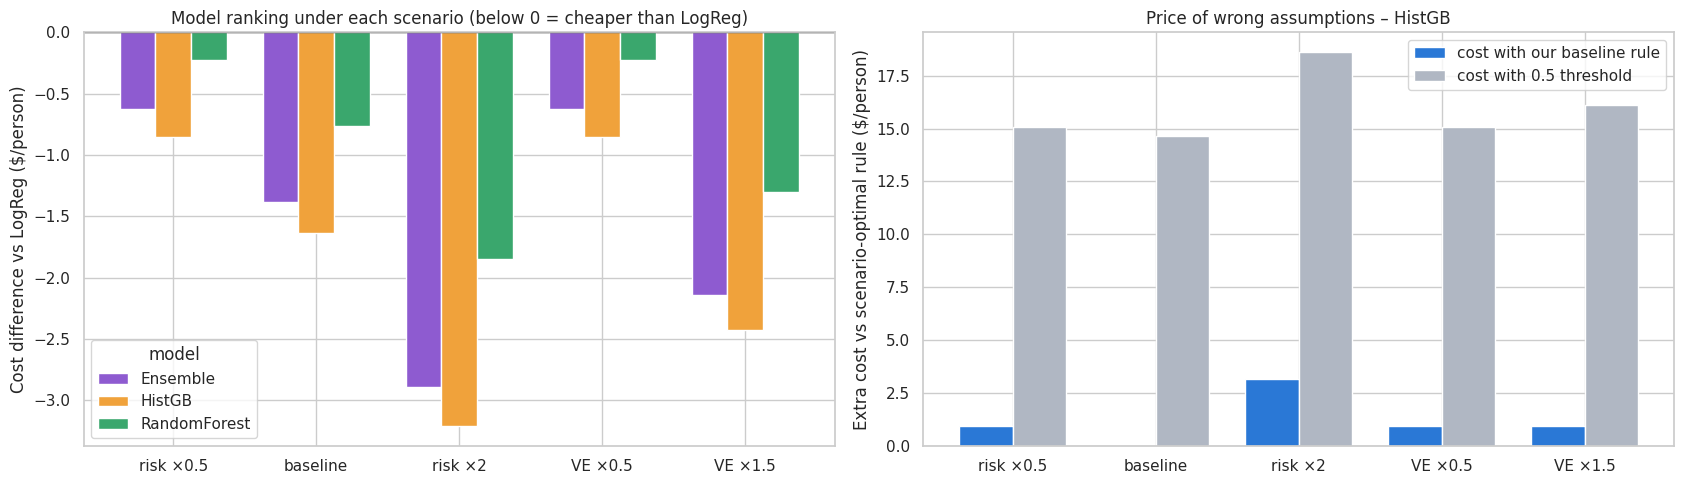

model,Ensemble,HistGB,LogReg,RandomForest
scenario,,,,
risk ×0.5,492.0,491.8,492.6,492.4
baseline,802.0,801.7,803.4,802.6
risk ×2,1393.9,1393.6,1396.8,1394.9
VE ×0.5,879.7,879.4,880.3,880.1
VE ×1.5,724.3,724.0,726.5,725.2


In [29]:
scenarios = {"risk ×0.5": dict(risk_scale=0.5), "baseline": {}, "risk ×2": dict(risk_scale=2.0),
             "VE ×0.5": dict(ve_scale=0.5), "VE ×1.5": dict(ve_scale=1.5)}
rows = []
for sc, kw in scenarios.items():
    for n, qq in oof.items():
        rows.append({"scenario": sc, "model": n,
                     # decisions made knowing the true scenario
                     "cost if assumptions right": cost_per_person(y_all, cost_optimal_decision(qq, X_all, **kw), X_all, **kw),
                     # decisions made with OUR baseline assumptions, scored under the scenario
                     "cost with our baseline rule": cost_per_person(y_all, cost_optimal_decision(qq, X_all), X_all, **kw),
                     "cost with 0.5 threshold": cost_per_person(y_all, (qq >= 0.5).astype(int), X_all, **kw)})
sens = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 2, figsize=(17, 5))
piv = sens.pivot(index="scenario", columns="model", values="cost with our baseline rule").reindex(list(scenarios))
piv.sub(piv["LogReg"], axis=0).drop(columns="LogReg").plot.bar(ax=ax[0], color=["#8e5bd0", "#f0a23b", "#3aa76d"], width=0.75)
ax[0].axhline(0, color="k", lw=1); ax[0].tick_params(axis="x", rotation=0)
ax[0].set_ylabel("Cost difference vs LogReg ($/person)"); ax[0].set_xlabel("")
ax[0].set_title("Model ranking under each scenario (below 0 = cheaper than LogReg)")

e = sens[sens["model"] == cv_best_name].set_index("scenario").reindex(list(scenarios))
(e[["cost with our baseline rule", "cost with 0.5 threshold"]].sub(e["cost if assumptions right"], axis=0)
   ).plot.bar(ax=ax[1], color=["#2a78d6", "#b0b7c3"], width=0.75)
ax[1].tick_params(axis="x", rotation=0); ax[1].set_xlabel("")
ax[1].set_ylabel("Extra cost vs scenario-optimal rule ($/person)")
ax[1].set_title(f"Price of wrong assumptions – {cv_best_name}")
savefig("14_sensitivity_analysis")
sens.pivot(index="scenario", columns="model", values="cost with our baseline rule").reindex(list(scenarios)).round(1)

**Result.** (1) The ranking is stable: HistGB and the ensemble beat logistic regression in every scenario, HistGB always first. So our submission order does not depend on the exact hospitalisation numbers. (2) Deciding with our baseline assumptions when the truth is different costs at most ~\$3 per person extra (when the real risk is double), whereas the naive 0.5 threshold loses \$15-19 in every scenario. The per-person rule is therefore robust: being roughly right about *who is high-risk* matters far more than the exact percentages.

## 8. Explainable AI

Three complementary views:
* **Permutation importance** (model-agnostic): shuffle one original column on the hold-out set and measure how much the log-loss gets worse.
* **Logistic regression coefficients**: direction and size of each effect.
* **Partial dependence**: how the predicted probability moves when one feature changes and everything else stays as it is.

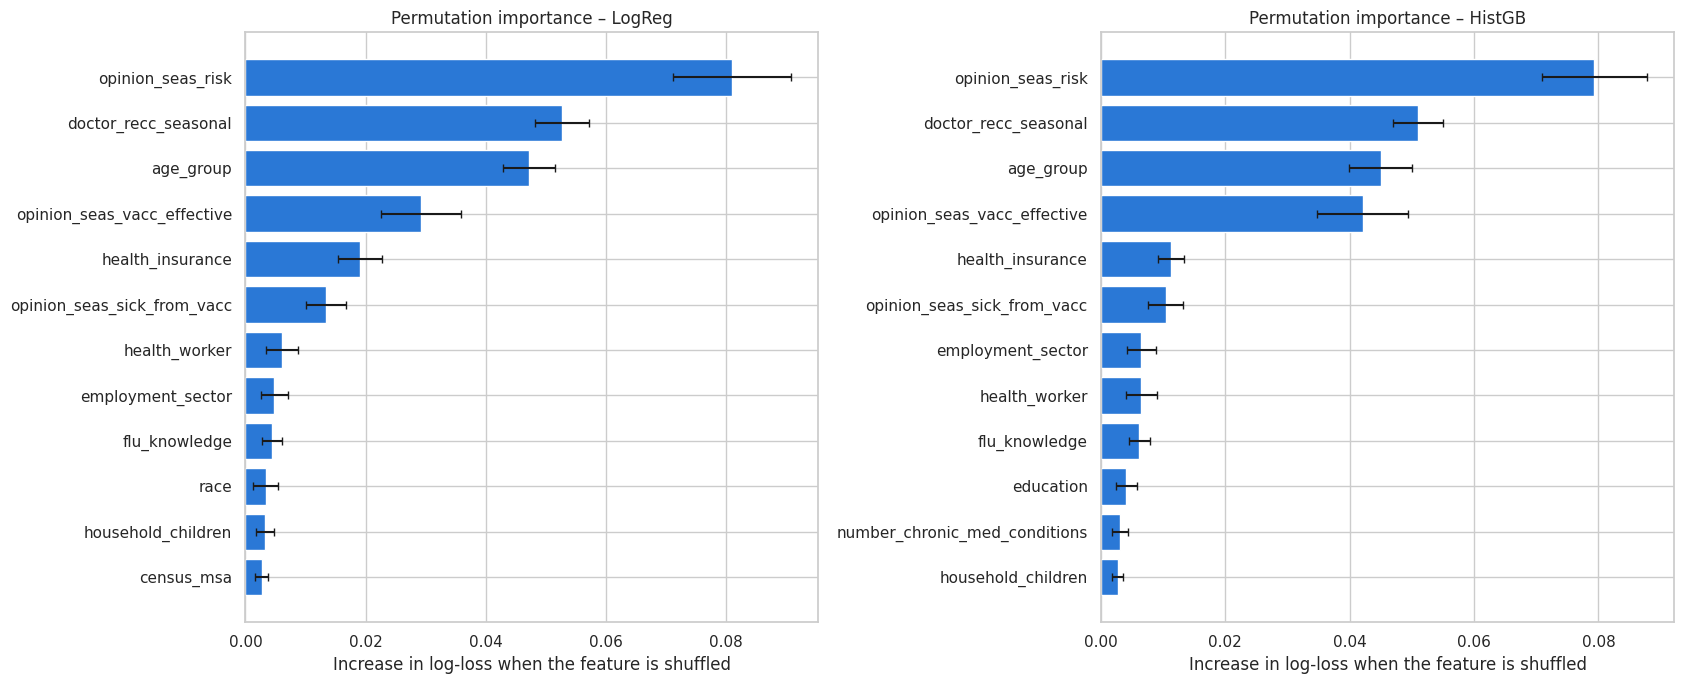

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7), sharex=False)
perm = {}
for ax, n in zip(axes, ["LogReg", "HistGB"]):
    pi = permutation_importance(fitted[n], X_hold, y_hold, scoring="neg_log_loss",
                                n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1)
    perm[n] = pd.DataFrame({"mean": pi.importances_mean, "std": pi.importances_std}, index=FEATURES).sort_values("mean")
    top = perm[n].tail(12)
    ax.barh(top.index, top["mean"], xerr=top["std"], color="#2a78d6", capsize=3)
    ax.set_xlabel("Increase in log-loss when the feature is shuffled"); ax.set_title(f"Permutation importance – {n}")
savefig("15_permutation_importance")

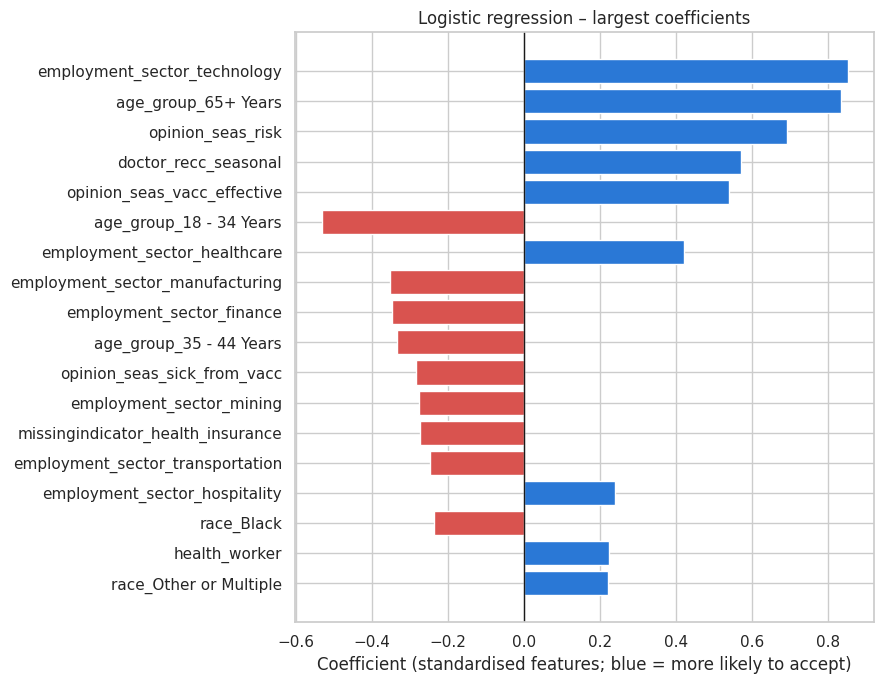

In [31]:
lr = fitted["LogReg"]
coef = pd.Series(lr.named_steps["clf"].coef_[0],
                 index=lr.named_steps["prep"].named_steps["ct"].get_feature_names_out())
top = coef.reindex(coef.abs().sort_values().index).tail(18)
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.index, top.values, color=["#d9534f" if v < 0 else "#2a78d6" for v in top.values])
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("Coefficient (standardised features; blue = more likely to accept)")
ax.set_title("Logistic regression – largest coefficients")
savefig("16_logreg_coefficients")

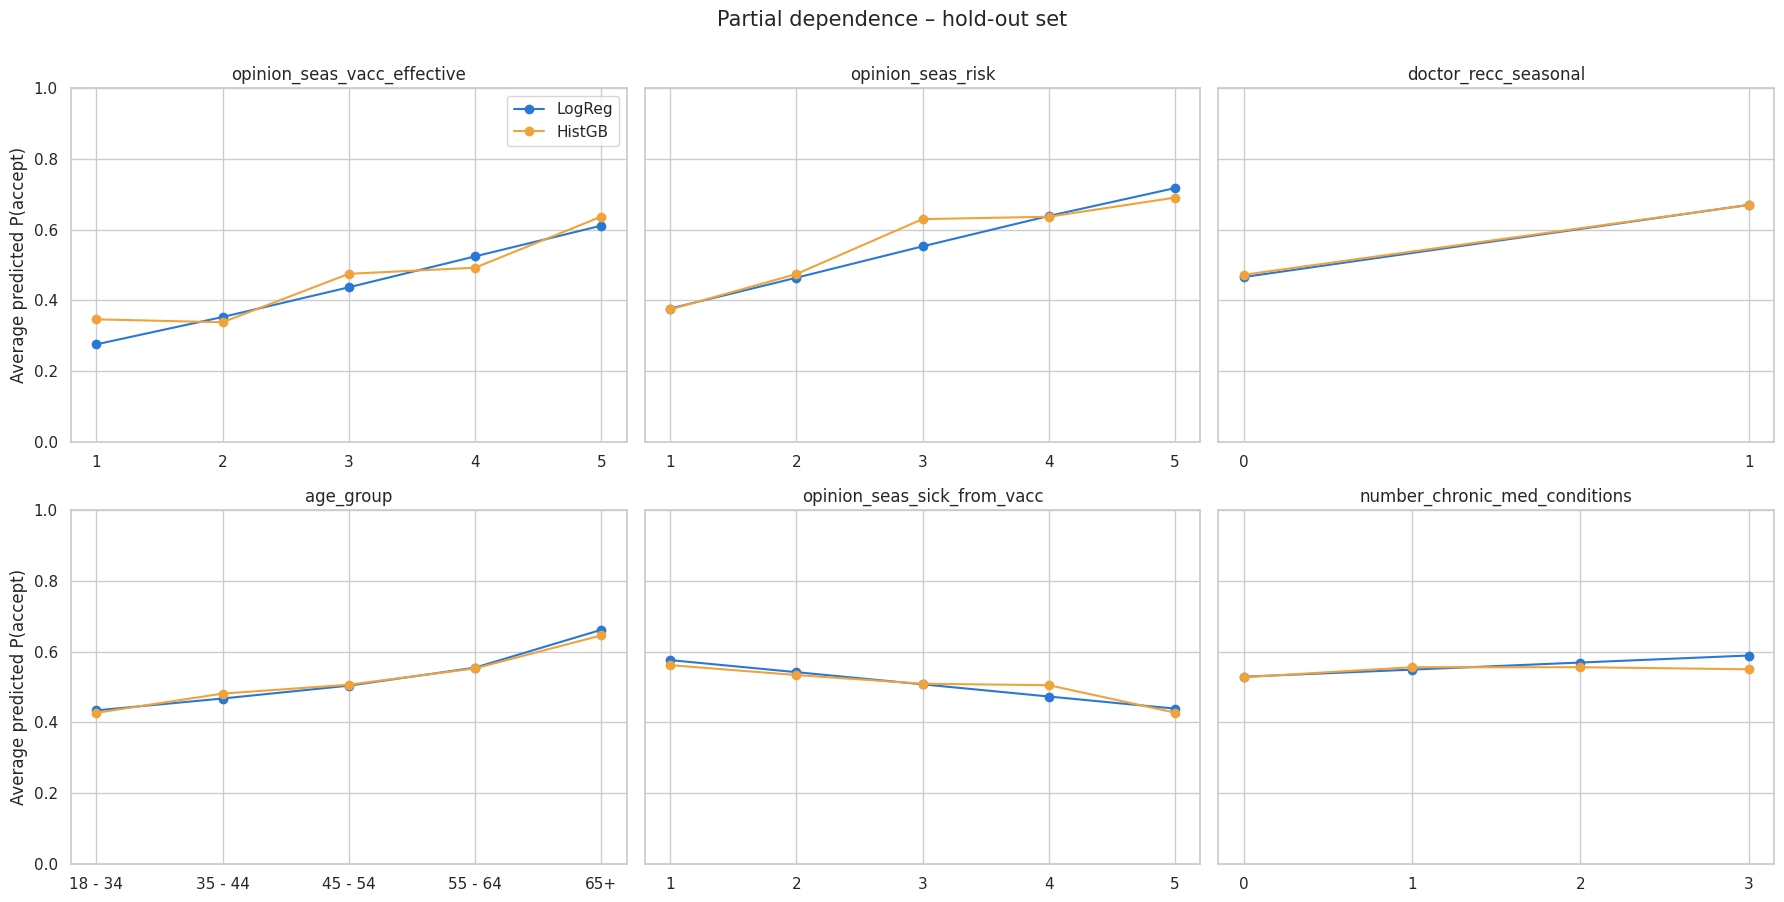

In [32]:
def partial_dependence_manual(model, X, feature, values):
    """Average predicted P(accept) when `feature` is set to each value for everybody."""
    out = []
    for v in values:
        Xm = X.copy(); Xm[feature] = v
        out.append(model.predict_proba(Xm)[:, 1].mean())
    return np.array(out)

pd_feats = {"opinion_seas_vacc_effective": [1, 2, 3, 4, 5], "opinion_seas_risk": [1, 2, 3, 4, 5],
            "doctor_recc_seasonal": [0, 1], "age_group": AGE_ORDER,
            "opinion_seas_sick_from_vacc": [1, 2, 3, 4, 5], "number_chronic_med_conditions": [0, 1, 2, 3]}
fig, axes = plt.subplots(2, 3, figsize=(18, 9), sharey=True)
for ax, (f, vals) in zip(axes.ravel(), pd_feats.items()):
    for n in ["LogReg", "HistGB"]:
        ax.plot([str(v).replace(" Years", "") for v in vals],
                partial_dependence_manual(fitted[n], X_hold, f, vals), marker="o", label=n, color=pal[n])
    ax.set_title(f); ax.set_ylim(0, 1)
axes[0, 0].set_ylabel("Average predicted P(accept)"); axes[1, 0].set_ylabel("Average predicted P(accept)")
axes[0, 0].legend()
fig.suptitle("Partial dependence – hold-out set", y=1.0, fontsize=15)
savefig("17_partial_dependence")

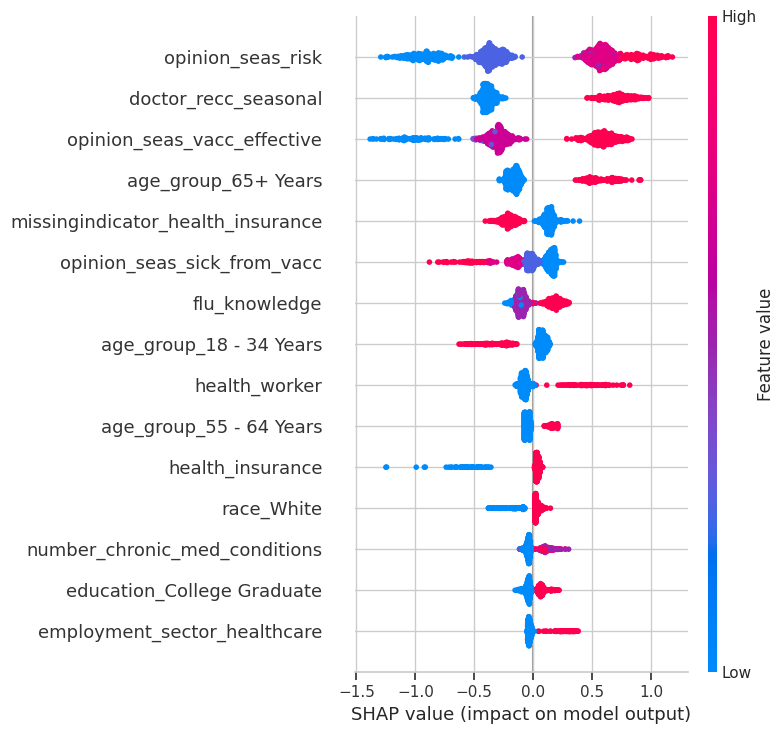

In [33]:
# Optional: SHAP values for the gradient-boosting model (in Colab run `!pip install shap` first)
try:
    try:
        import shap
    except ImportError:            # Colab does not ship shap
        import subprocess, sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"])
        import shap
    prep, clf = fitted["HistGB"].named_steps["prep"], fitted["HistGB"].named_steps["clf"]
    Xt = pd.DataFrame(prep.transform(X_hold), columns=prep.named_steps["ct"].get_feature_names_out())
    sv = shap.TreeExplainer(clf).shap_values(Xt)
    shap.summary_plot(sv, Xt, max_display=15, show=False)
    savefig("18_shap_summary")
except Exception as e:
    print("SHAP plot skipped:", e)

### What drives the predictions
* **Both models agree on the top four features:** perceived risk of flu, a doctor's recommendation, age group and belief that the vaccine works. Agreement between a linear and a tree model makes these findings more trustworthy than either alone.
* **Second tier:** health insurance, worry about getting sick from the vaccine (negative effect), being a health worker / working in healthcare.
* **Partial dependence** shows the effects are close to monotonic, which explains why logistic regression is nearly as good as boosting: there is little non-linear structure left to exploit.
* **Actionable reading for the town:** the features that matter most are *opinions* and *doctor contact* – things a public-health campaign can change – rather than fixed demographics.
* **Caveats:** permutation importance splits credit between correlated features (e.g. `health_worker` and the healthcare `employment_sector`), and these are associations in survey data, not proof of cause.

## 9. Submission files
Each candidate is refitted on **all** labelled data (train + hold-out) and applied to the test set. Files are numbered best → worst according to the cross-validated town cost.

In [34]:
X_test = test[FEATURES]
candidates = {  # name -> (model key, decision rule)
    "Ensemble_costrule": ("Ensemble", "rule"), "HistGB_costrule": ("HistGB", "rule"),
    "LogReg_costrule": ("LogReg", "rule"), "RandomForest_costrule": ("RandomForest", "rule"),
    "Ensemble_threshold05": ("Ensemble", "0.5"),
}
cv_cost = {c: (cv_results[m]["cost_rule" if r == "rule" else "cost_0.5"].mean(),
               cv_results[m]["cost_rule" if r == "rule" else "cost_0.5"].std()) for c, (m, r) in candidates.items()}
ranking = sorted(candidates, key=lambda c: cv_cost[c][0])

final_models = {m: clone(models[m]).fit(X_all, y_all) for m in {m for m, _ in candidates.values()}}
test_q = {m: fm.predict_proba(X_test)[:, 1] for m, fm in final_models.items()}

rows = []
for rank, c in enumerate(ranking, 1):
    m, r = candidates[c]
    pred = cost_optimal_decision(test_q[m], X_test) if r == "rule" else (test_q[m] >= 0.5).astype(int)
    fname = f"{SUB_DIR}/submission_{rank}_{c}.csv"
    pd.DataFrame({ID: test[ID], TARGET: pred.astype(float)}).to_csv(fname, index=False)
    rows.append({"rank": rank, "file": fname, "CV cost $/person": cv_cost[c][0], "CV std": cv_cost[c][1],
                 "hold-out cost $/person": hold_table.loc[m, "cost_rule" if r == "rule" else "cost_0.5"],
                 "vaccines sent on test": int(pred.sum()), "share sent": pred.mean()})
sub_table = pd.DataFrame(rows).set_index("rank")
sub_table.round(3)

,file,CV cost $/person,CV std,hold-out cost $/person,vaccines sent on test,share sent
rank,,,,,,
1,submissions/submission_1_HistGB_costrule.csv,795.969,38.257,823.665,1967,0.414
2,submissions/submission_2_Ensemble_costrule.csv,796.544,38.354,822.413,1924,0.405
3,submissions/submission_3_RandomForest_costrule...,798.227,38.107,823.312,1939,0.408
4,submissions/submission_4_LogReg_costrule.csv,798.383,39.309,824.508,1946,0.410
5,submissions/submission_5_Ensemble_threshold05.csv,811.438,38.962,837.587,2700,0.569


Please upload dataset_A_example_submission.csv (you can select all three CSV files at once)


Saving dataset_A_example_submission.csv to dataset_A_example_submission.csv
Saving dataset_A_testing.csv to dataset_A_testing (1).csv
Saving dataset_A_training.csv to dataset_A_training (1).csv
All 5 files match the example format: ['respondent_id', 'seasonal_vaccine'] 4749 rows


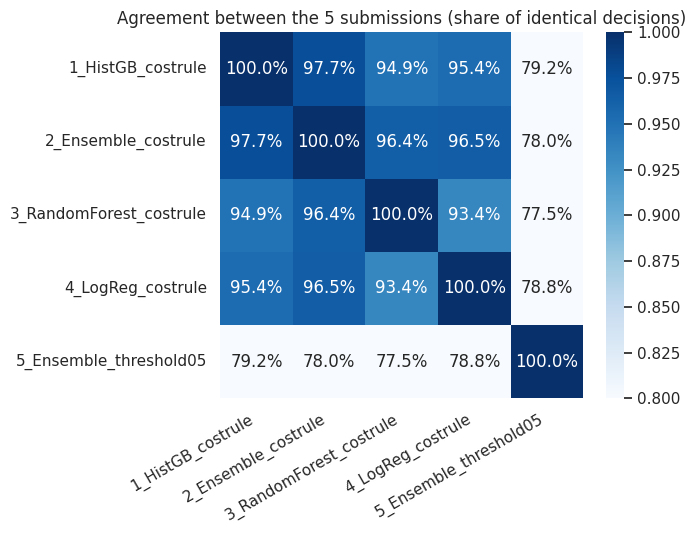

In [35]:
# Sanity checks against the example submission format
example = load("dataset_A_example_submission.csv")
for f in sub_table["file"]:
    s = pd.read_csv(f)
    assert list(s.columns) == list(example.columns), f
    assert (s[ID] == example[ID]).all() and len(s) == len(example), f
    assert s[TARGET].isin([0.0, 1.0]).all(), f
print("All 5 files match the example format:", list(example.columns), len(example), "rows")

agree = pd.DataFrame({f.split("submission_")[1][:-4]: pd.read_csv(f)[TARGET] for f in sub_table["file"]})
fig, ax = plt.subplots(figsize=(7, 5.5))
same = pd.DataFrame([[(agree[a] == agree[b]).mean() for b in agree] for a in agree],
                    index=agree.columns, columns=agree.columns)
sns.heatmap(same, annot=True, fmt=".1%", cmap="Blues", vmin=0.8, vmax=1, ax=ax)
ax.set_title("Agreement between the 5 submissions (share of identical decisions)")
plt.xticks(rotation=30, ha="right")
savefig("19_submission_agreement")

## Summary

**Submission order (best → worst) and why**
1. **HistGB + cost rule** – lowest cross-validated cost, cheaper than logistic regression in 12/15 paired folds, best in every sensitivity scenario.
2. **Ensemble + cost rule** – statistically tied with #1 (best on the hold-out), lower variance by construction.
3. **Random forest + cost rule**
4. **Logistic regression + cost rule** – simplest and most explainable, only ~\$2 per person behind.
5. **Ensemble + 0.5 threshold** – deliberate control: same model as #2 without our cost rule. If it scores clearly worse on the hidden test set, that confirms the metric analysis.

**For a non-expert audience**
* We built a tool that decides, person by person, whether to post a flu vaccine.
* It combines two questions: *how likely is this person to accept it?* (learned from the survey) and *how much would the town save if they do?* (higher for older people and people with chronic conditions).
* Recommendation: post vaccines to almost all over-65s, and to younger adults only when we are very confident they will take it.
* Expected saving with our assumptions: about \$140 per resident compared with sending no vaccines, and about \$15 per resident compared with a standard "more likely than not" prediction.
* People are most likely to accept when they think flu is a real risk to them, their doctor recommended it, and they believe the vaccine works.

**Honest limitations**
* Hospitalisation probabilities are researched assumptions, not data from this town; the organisers' figures may differ (section 7 shows the ranking survives ×0.5 to ×2 changes).
* Differences between our top models are smaller than the noise of one validation split.
* Survey answers are self-reported and the model shows associations, not causes.